In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import Dataset, DataLoader, random_split
import torch.optim as optim
import torch.nn as nn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
from torchvision import transforms

In [2]:
train_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor()
])
base_transforms = transforms.Compose([transforms.ToTensor()])

In [3]:
class DigitDataset(Dataset):
    def __init__(self, df, is_test, transform = None):
        if not is_test:
            self.x = torch.tensor(df.drop("label", axis = 1).values, dtype=torch.uint8)
            self.y = torch.tensor(df["label"].values, dtype=torch.long)
        else:
            self.x = torch.tensor(df.values, dtype=torch.uint8)
            self.y = None 
            
        self.x = self.x.reshape(-1, 1, 28, 28)
        self.transform = transform
        
    def __len__(self):
        return len(self.x)
    
    def __getitem__(self, idx):
        image = self.x[idx]
        if self.transform is not None:
            image = self.transform(image)
        else:
            image = image.float() / 255.0
        if self.y is not None:
            return image, self.y[idx]
        return image

In [4]:
BATCH_SIZE = 250
raw_df = pd.read_csv("train.csv")
train_raw = raw_df.sample(frac=0.9, random_state=42)
val_raw = raw_df.drop(train_raw.index)
train_df_plain = DigitDataset(train_raw, is_test=False, transform=None)
train_df_aug = DigitDataset(train_raw, is_test=False, transform=train_transforms)
val_df = DigitDataset(val_raw, is_test=False, transform=None)
train_loader_plain = DataLoader(train_df_plain, batch_size=BATCH_SIZE, shuffle=True)
train_loader_aug = DataLoader(train_df_aug, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_df, batch_size=BATCH_SIZE, shuffle=False)

In [5]:
class ConvolutionalNeuralNetwork(nn.Module):
    def __init__(self, kernel_sizes):
        super(ConvolutionalNeuralNetwork, self).__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=kernel_sizes[0], padding = 2)
        self.pool1 = nn.MaxPool2d(2,2)
        self.drop1 = nn.Dropout(0.25)
        
        self.conv2 = nn.Conv2d(8, 16, kernel_size=kernel_sizes[1], padding = 1)
        self.pool2 = nn.MaxPool2d(2,2)
        self.drop2 = nn.Dropout(0.25)
        
        self.flatten_size = self.get_flatten_size()
        
        self.fc1 = nn.Linear(self.flatten_size, 256)
        self.drop3 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 10)
        
    def forward(self,x):
        x = self.drop1(self.pool1(torch.relu(self.conv1(x))))
        x = self.drop2(self.pool2(torch.relu(self.conv2(x))))
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.drop3(x)
        return self.fc2(x)
    
    def get_flatten_size(self):
        with torch.no_grad():
            x = torch.zeros(1,1,28,28)
            x = self.pool1(torch.relu(self.conv1(x)))
            x = self.pool2(torch.relu(self.conv2(x)))
            return x.numel()
    

In [6]:
def evaluate_model(model, loader):
    model.eval()
    all_predictions = []
    all_labels = []
    running_loss = 0.0
    criterion = nn.CrossEntropyLoss()
    
    with torch.no_grad():
        for images, labels in loader:
            predicted_logits = model(images)
            predicted_probabilities = torch.softmax(predicted_logits, dim = 1)
            _, prediction = torch.max(predicted_probabilities, 1)
            loss = criterion(predicted_logits, labels)
            running_loss += loss.item()
            all_predictions.extend(prediction.numpy())
            all_labels.extend(labels.numpy())
            
        epoch_loss = running_loss / len(loader)
            
        accuracy = accuracy_score(all_labels, all_predictions) 
        precision = precision_score(all_labels, all_predictions, average = 'macro')
        recall = recall_score(all_labels, all_predictions, average = 'macro')
        f1 = f1_score(all_labels, all_predictions, average = 'macro')
    return accuracy, precision, recall, f1, epoch_loss      

In [7]:
def perform_learning(model, EPOCHS, optimizer, train_loader, val_loader):
    history = {
    'train_loss': [], 'train_accuracy': [],
    'val_precision': [], 'val_recall': [],
    'val_accuracy': [], 'val_f1': [],
    'val_loss': []
    }
    criterion = nn.CrossEntropyLoss()
    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            batch_loss = loss.item()
            running_loss += batch_loss
        
        epoch_loss = running_loss / len(train_loader)
        
        train_accuracy, train_precision, train_recall, train_f1, _ = evaluate_model(model, train_loader)
        val_accuracy, val_precision, val_recall, val_f1, val_loss = evaluate_model(model, val_loader)
        
        history['train_loss'].append(epoch_loss)
        history['train_accuracy'].append(train_accuracy)
        history['val_precision'].append(val_precision)
        history['val_recall'].append(val_recall)
        history['val_accuracy'].append(val_accuracy)
        history['val_f1'].append(val_f1)
        history['val_loss'].append(val_loss)
        
        print(f"Epoch [{epoch+1}/{EPOCHS}]")
        print(f"  Train -> Loss: {epoch_loss:.4f} | Accuracy: {train_accuracy:.4f} | Precision: {train_precision:.4f} | Recall: {train_recall:.4f} | F1: {train_f1:.4f}")
        print(f"  Valid -> Loss: {val_loss:.4f} | Accuracy: {val_accuracy:.4f} | Precision: {val_precision:.4f} | Recall: {val_recall:.4f} | F1: {val_f1:.4f}")
        print("-" * 100)
    return history

In [8]:
def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    fig.suptitle(title, fontsize=16)

    ax1.plot(history['train_loss'], label='Train Loss', color='blue')
    ax1.plot(history['val_loss'], label='Validation Loss', color='orange')
    ax1.set_title('Training Loss')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    
    ax2.plot(history['train_accuracy'], label='Train Accuracy', color='blue')
    ax2.plot(history['val_accuracy'], label='Validation Accuracy', color='orange')
    ax2.set_title('Accuracy Evolution')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy')
    ax2.legend()

    plt.show()

In [9]:
def plot_final_analysis(model, loader, title="Confusion Matrix"):
    model.eval()
    all_predictions, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_predictions.extend(preds.numpy())
            all_labels.extend(labels.numpy())

    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay.from_predictions(all_labels, all_predictions, ax=ax, cmap='Blues')
    ax.grid(False)
    ax.set_title(title)
    plt.show()

In [10]:
results_summary = []

In [10]:
def run_experiment(kernel_sizes, optimizer_name, epochs, train_loader, val_loader, augmentation = False):
    print(f"Experiment with kernel {kernel_sizes} and optimizer: {optimizer_name} ")
    model = ConvolutionalNeuralNetwork(kernel_sizes)
    optimizer_dictionary = {
    "Adam": optim.Adam(model.parameters(), lr=0.001),
    "SGD": optim.SGD(model.parameters(), lr=0.01, momentum=0.9), 
    "RMSProp": optim.RMSprop(model.parameters(), lr=0.001)
    }
    optimizer = optimizer_dictionary[optimizer_name]

    history = perform_learning(model, epochs, optimizer, train_loader, val_loader)
    plot_history(history, f"Experiment: {kernel_sizes} with {optimizer_name}")
    plot_final_analysis(model, val_loader)
    results_summary.append({
        "Model": "CNN-Base",
        "Kernels": str(kernel_sizes),
        "Optimizer": optimizer_name,
        "Augmentation": augmentation,
        "Final Validation Accuracy": history['val_accuracy'][-1],
        "Final Validation Precision": history['val_precision'][-1],
        "Final Validation Recall": history['val_recall'][-1],
        "Final Validation F1-Score": history['val_f1'][-1],
        "Epochs": epochs
    })
    return history
    

In [11]:
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size = 5, padding = 2)
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)
        
        self.conv2 = nn.Conv2d(6, 16, kernel_size = 5)
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)
        
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
        
    def forward(self, x):
        x = torch.tanh(self.conv1(x))
        x = self.pool1(x)
        x = torch.tanh(self.conv2(x))
        x = self.pool2(x)
        x = x.view(x.size(0), -1)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = self.fc3(x)
        return x

In [12]:
def run_experiment_with_lenet5(optimizer_name, epochs, train_loader, val_loader, augmentation = False):
    print(f"Experiment with LeNet-5 and optimizer: {optimizer_name} ")
    model = LeNet5()
    optimizer_dictionary = {
    "Adam": optim.Adam(model.parameters(), lr=0.001),
    "SGD": optim.SGD(model.parameters(), lr=0.01, momentum=0.9), 
    "RMSProp": optim.RMSprop(model.parameters(), lr=0.001)
    }
    optimizer = optimizer_dictionary[optimizer_name]

    history = perform_learning(model, epochs, optimizer, train_loader, val_loader)
    plot_history(history, f"Experiment: LeNet-5 with {optimizer_name}")
    plot_final_analysis(model, val_loader)
    results_summary.append({
        "Model": "Le-Net5",
        "Kernels": "[(5,5), (5,5)]",
        "Optimizer": optimizer_name,
        "Augmentation": augmentation,
        "Final Validation Accuracy": history['val_accuracy'][-1],
        "Final Validation Precision": history['val_precision'][-1],
        "Final Validation Recall": history['val_recall'][-1],
        "Final Validation F1-Score": history['val_f1'][-1],
        "Epochs": epochs
    })
    return history
    

In [13]:
class DeepConvolutionalNeuralNetwork(nn.Module):
    def __init__(self, kernel_sizes): 
        super(DeepConvolutionalNeuralNetwork, self).__init__()

        self.conv1 = nn.Conv2d(1, 8, kernel_size=kernel_sizes[0], padding=2)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.drop1 = nn.Dropout(0.25)
        
        self.conv2 = nn.Conv2d(8, 16, kernel_size=kernel_sizes[1], padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)
        self.drop2 = nn.Dropout(0.25)

        self.conv3 = nn.Conv2d(16, 32, kernel_size=kernel_sizes[2], padding=1)
        self.pool3 = nn.MaxPool2d(2, 2)
        self.drop3 = nn.Dropout(0.25)
        
        self.flatten_size = self.get_flatten_size()
        
        self.fc1 = nn.Linear(self.flatten_size, 256)
        self.drop4 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 10)
        
    def forward(self, x):
        x = self.drop1(self.pool1(torch.relu(self.conv1(x))))
        x = self.drop2(self.pool2(torch.relu(self.conv2(x))))
        x = self.drop3(self.pool3(torch.relu(self.conv3(x)))) 
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.drop4(x)
        return self.fc2(x)
    
    def get_flatten_size(self):
        with torch.no_grad():
            x = torch.zeros(1, 1, 28, 28)
            x = self.pool1(torch.relu(self.conv1(x)))
            x = self.pool2(torch.relu(self.conv2(x)))
            x = self.pool3(torch.relu(self.conv3(x))) 
            return x.numel()

In [14]:
def run_experiment_with_deep_network(kernel_sizes, optimizer_name, epochs, train_loader, val_loader, augmentation = False):
    print(f"Experiment with deep network with kernel {kernel_sizes} and optimizer: {optimizer_name} ")
    model = DeepConvolutionalNeuralNetwork(kernel_sizes)
    optimizer_dictionary = {
    "Adam": optim.Adam(model.parameters(), lr=0.001),
    "SGD": optim.SGD(model.parameters(), lr=0.01, momentum=0.9), 
    "RMSProp": optim.RMSprop(model.parameters(), lr=0.001)
    }
    optimizer = optimizer_dictionary[optimizer_name]

    history = perform_learning(model, epochs, optimizer, train_loader, val_loader)
    plot_history(history, f"Experiment: {kernel_sizes} with {optimizer_name}")
    plot_final_analysis(model, val_loader)
    results_summary.append({
        "Model": "CNN-Deep",
        "Kernels": str(kernel_sizes),
        "Optimizer": optimizer_name,
        "Augmentation": augmentation,
        "Final Validation Accuracy": history['val_accuracy'][-1],
        "Final Validation Precision": history['val_precision'][-1],
        "Final Validation Recall": history['val_recall'][-1],
        "Final Validation F1-Score": history['val_f1'][-1],
        "Epochs": epochs
    })
    return history
    

In [16]:
configs = [[(5,5), (3,3)], [(3,3), (3,3)], [(7,1), (1,7)], [(7,7), (5,5)], [(3,1), (1,3)]]
deep_configs = [
    [(5,5), (3,3), (3,3)], 
    [(3,3), (3,3), (3,3)],
    [(7,1), (1,7), (3,3)]
]

Experiment with kernel [(5, 5), (3, 3)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 0.8556 | Accuracy: 0.9296 | Precision: 0.9295 | Recall: 0.9291 | F1: 0.9290
  Valid -> Loss: 0.2439 | Accuracy: 0.9336 | Precision: 0.9332 | Recall: 0.9328 | F1: 0.9329
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.2888 | Accuracy: 0.9612 | Precision: 0.9612 | Recall: 0.9611 | F1: 0.9611
  Valid -> Loss: 0.1374 | Accuracy: 0.9607 | Precision: 0.9602 | Recall: 0.9605 | F1: 0.9603
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.2045 | Accuracy: 0.9700 | Precision: 0.9698 | Recall: 0.9700 | F1: 0.9698
  Valid -> Loss: 0.1053 | Accuracy: 0.9671 | Precision: 0.9666 | Recall: 0.9669 | F1: 0.9666
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.1706 | 

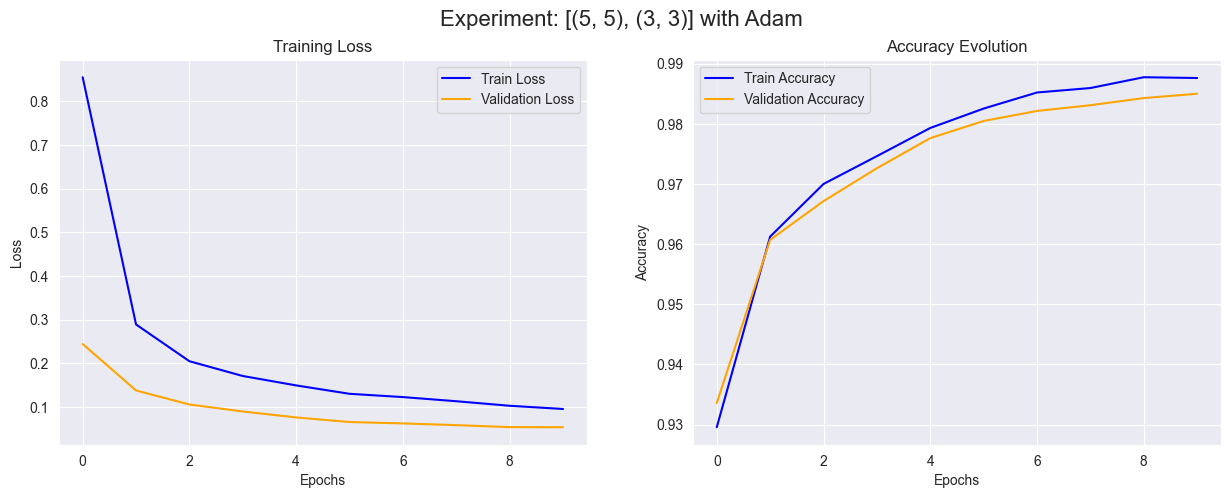

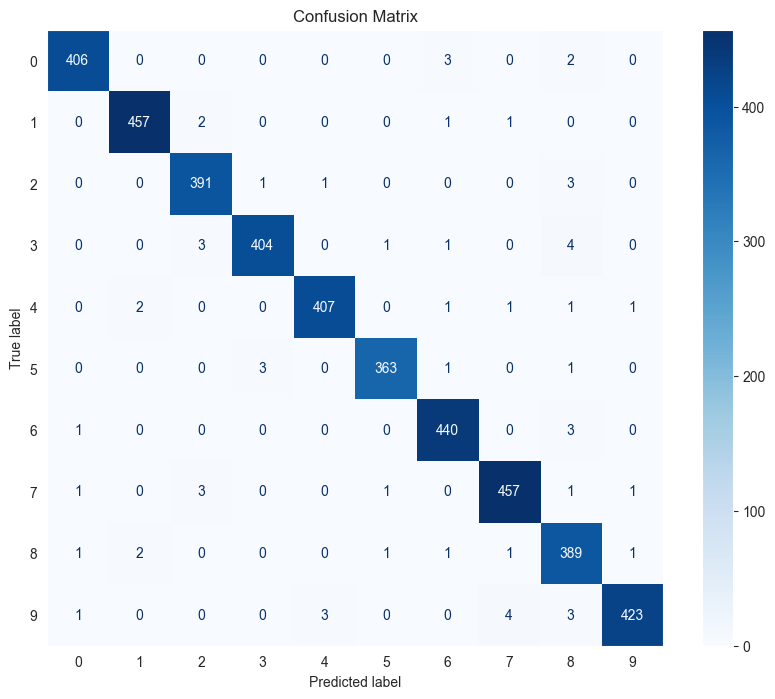

Experiment with kernel [(3, 3), (3, 3)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 0.8664 | Accuracy: 0.9240 | Precision: 0.9233 | Recall: 0.9236 | F1: 0.9231
  Valid -> Loss: 0.2632 | Accuracy: 0.9348 | Precision: 0.9341 | Recall: 0.9342 | F1: 0.9339
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.3175 | Accuracy: 0.9546 | Precision: 0.9544 | Recall: 0.9543 | F1: 0.9542
  Valid -> Loss: 0.1519 | Accuracy: 0.9564 | Precision: 0.9563 | Recall: 0.9558 | F1: 0.9560
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.2202 | Accuracy: 0.9665 | Precision: 0.9668 | Recall: 0.9663 | F1: 0.9664
  Valid -> Loss: 0.1112 | Accuracy: 0.9688 | Precision: 0.9693 | Recall: 0.9683 | F1: 0.9686
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.1749 | 

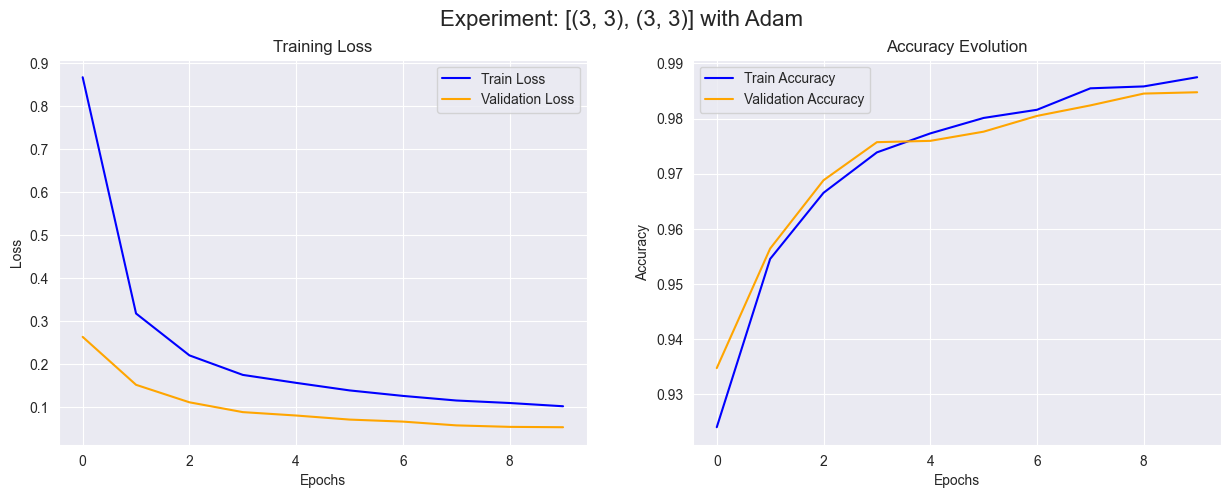

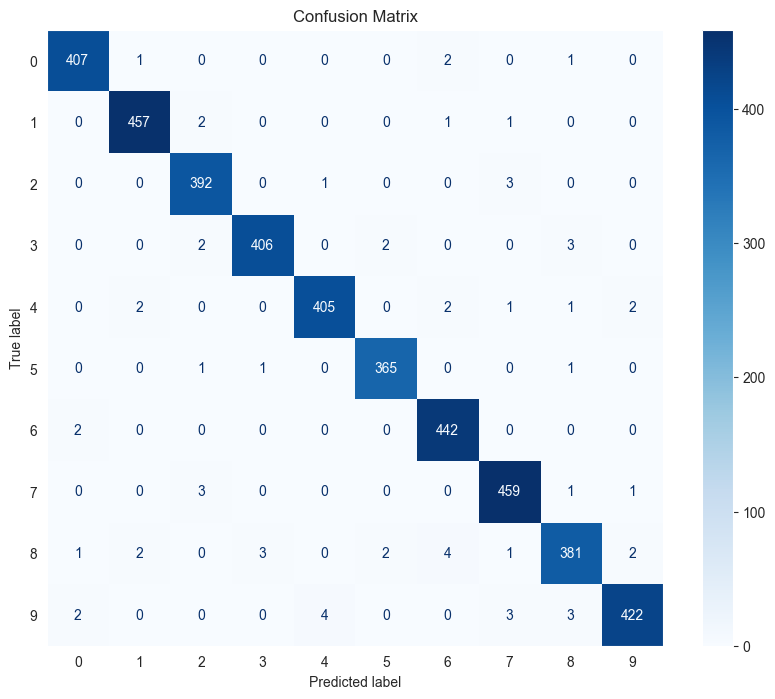

Experiment with kernel [(7, 1), (1, 7)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 1.1171 | Accuracy: 0.8819 | Precision: 0.8875 | Recall: 0.8796 | F1: 0.8806
  Valid -> Loss: 0.4117 | Accuracy: 0.8829 | Precision: 0.8889 | Recall: 0.8800 | F1: 0.8815
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.4524 | Accuracy: 0.9256 | Precision: 0.9274 | Recall: 0.9248 | F1: 0.9253
  Valid -> Loss: 0.2451 | Accuracy: 0.9321 | Precision: 0.9337 | Recall: 0.9311 | F1: 0.9316
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.3334 | Accuracy: 0.9491 | Precision: 0.9492 | Recall: 0.9486 | F1: 0.9488
  Valid -> Loss: 0.1762 | Accuracy: 0.9507 | Precision: 0.9507 | Recall: 0.9499 | F1: 0.9502
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.2732 | 

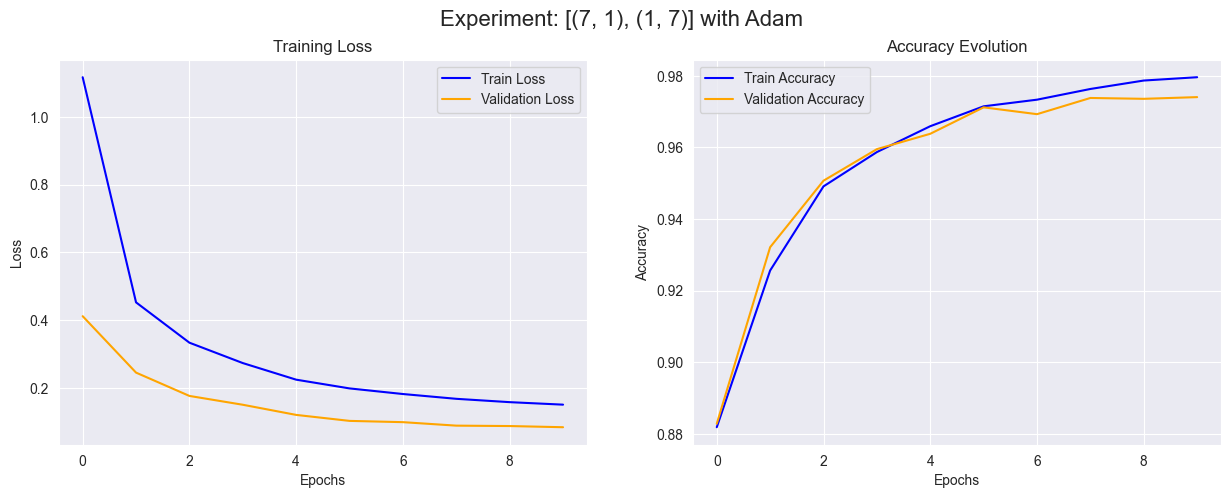

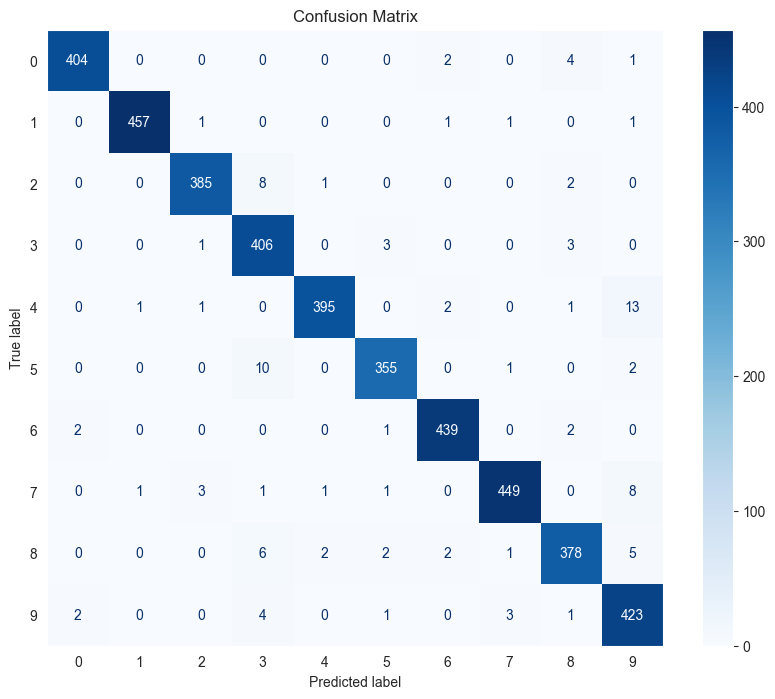

Experiment with kernel [(7, 7), (5, 5)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 0.8021 | Accuracy: 0.9383 | Precision: 0.9389 | Recall: 0.9377 | F1: 0.9379
  Valid -> Loss: 0.2079 | Accuracy: 0.9390 | Precision: 0.9399 | Recall: 0.9382 | F1: 0.9386
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.2448 | Accuracy: 0.9671 | Precision: 0.9672 | Recall: 0.9669 | F1: 0.9670
  Valid -> Loss: 0.1163 | Accuracy: 0.9657 | Precision: 0.9653 | Recall: 0.9652 | F1: 0.9652
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.1712 | Accuracy: 0.9756 | Precision: 0.9755 | Recall: 0.9755 | F1: 0.9755
  Valid -> Loss: 0.0887 | Accuracy: 0.9760 | Precision: 0.9757 | Recall: 0.9755 | F1: 0.9755
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.1378 | 

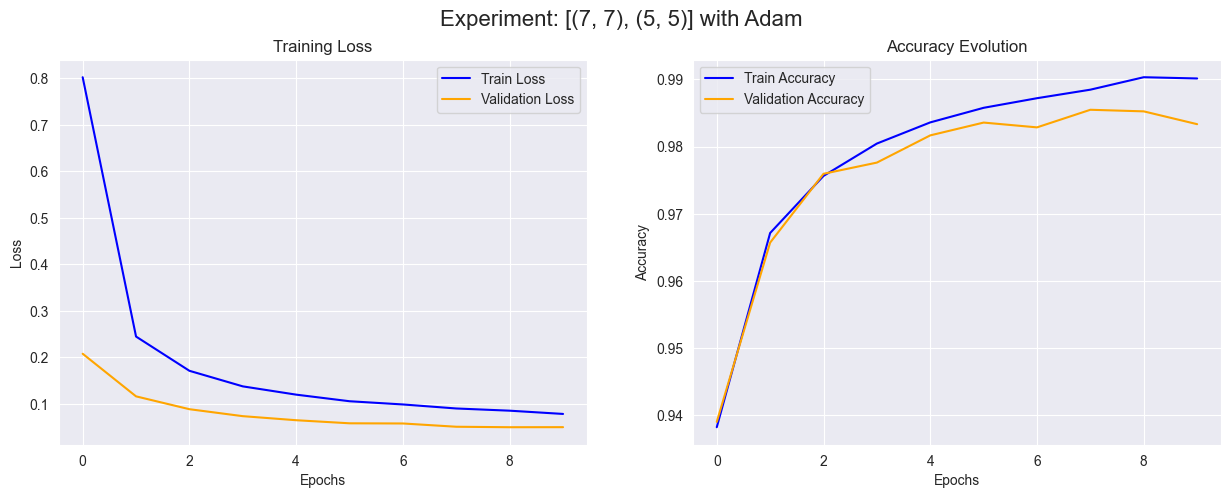

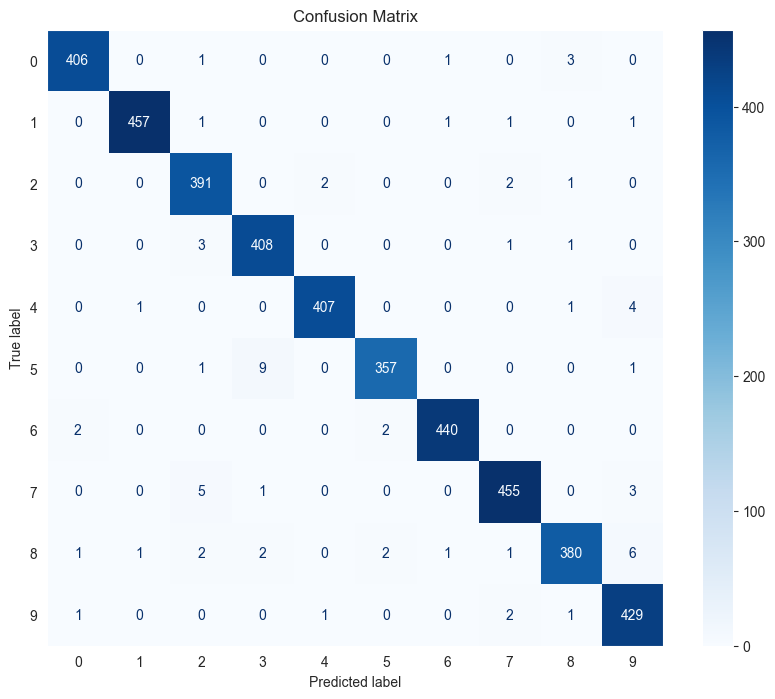

Experiment with kernel [(3, 1), (1, 3)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 1.2673 | Accuracy: 0.8510 | Precision: 0.8616 | Recall: 0.8486 | F1: 0.8487
  Valid -> Loss: 0.5173 | Accuracy: 0.8614 | Precision: 0.8702 | Recall: 0.8577 | F1: 0.8589
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.5568 | Accuracy: 0.9057 | Precision: 0.9071 | Recall: 0.9051 | F1: 0.9049
  Valid -> Loss: 0.3340 | Accuracy: 0.9093 | Precision: 0.9106 | Recall: 0.9081 | F1: 0.9081
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.4299 | Accuracy: 0.9256 | Precision: 0.9266 | Recall: 0.9253 | F1: 0.9253
  Valid -> Loss: 0.2771 | Accuracy: 0.9283 | Precision: 0.9289 | Recall: 0.9271 | F1: 0.9274
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.3738 | 

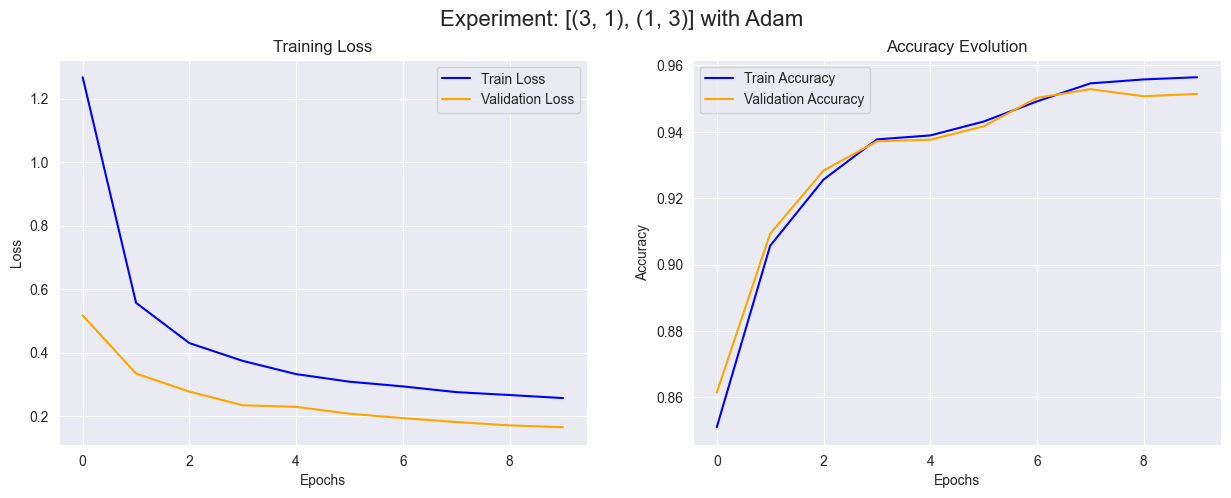

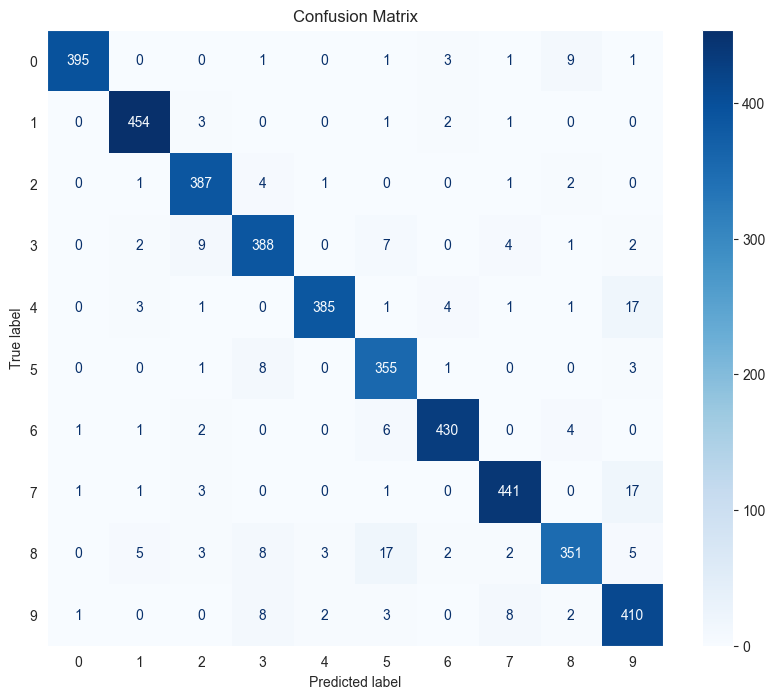

In [17]:
for kernel in configs:
    run_experiment(kernel, "Adam", 10, train_loader_plain, val_loader)

Experiment with kernel [(5, 5), (3, 3)] and optimizer: RMSProp 
Epoch [1/10]
  Train -> Loss: 0.5282 | Accuracy: 0.9580 | Precision: 0.9582 | Recall: 0.9577 | F1: 0.9578
  Valid -> Loss: 0.1430 | Accuracy: 0.9567 | Precision: 0.9565 | Recall: 0.9564 | F1: 0.9563
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.1973 | Accuracy: 0.9672 | Precision: 0.9673 | Recall: 0.9673 | F1: 0.9671
  Valid -> Loss: 0.1058 | Accuracy: 0.9662 | Precision: 0.9661 | Recall: 0.9661 | F1: 0.9659
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.1565 | Accuracy: 0.9768 | Precision: 0.9770 | Recall: 0.9765 | F1: 0.9767
  Valid -> Loss: 0.0780 | Accuracy: 0.9781 | Precision: 0.9781 | Recall: 0.9776 | F1: 0.9778
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.1260

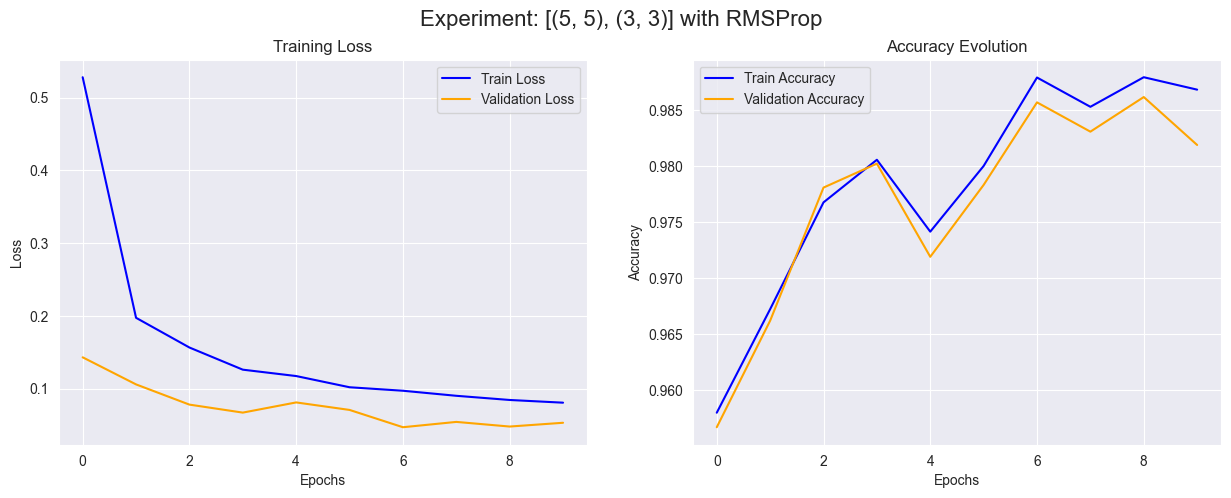

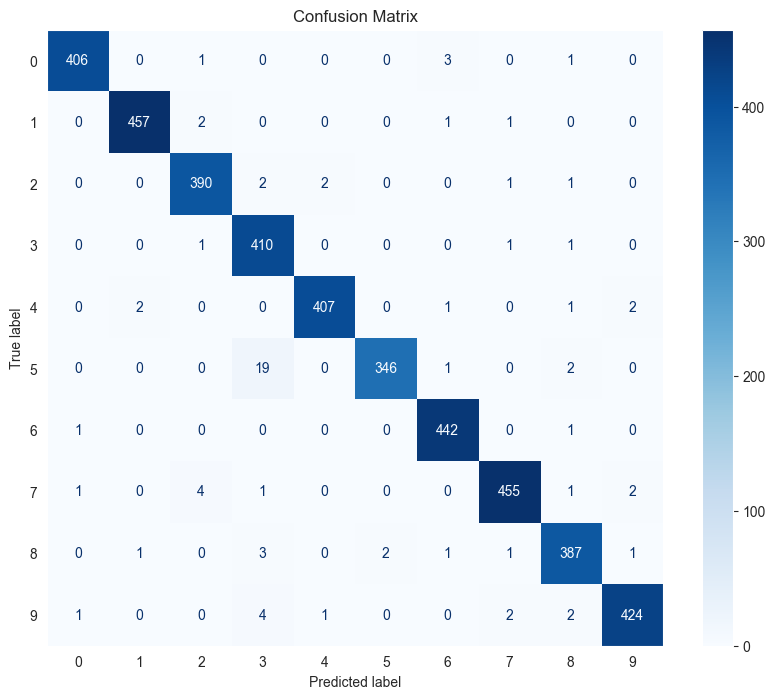

Experiment with kernel [(3, 3), (3, 3)] and optimizer: RMSProp 
Epoch [1/10]
  Train -> Loss: 0.6885 | Accuracy: 0.9384 | Precision: 0.9392 | Recall: 0.9378 | F1: 0.9381
  Valid -> Loss: 0.2141 | Accuracy: 0.9402 | Precision: 0.9410 | Recall: 0.9395 | F1: 0.9397
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.2754 | Accuracy: 0.9515 | Precision: 0.9520 | Recall: 0.9515 | F1: 0.9511
  Valid -> Loss: 0.1549 | Accuracy: 0.9524 | Precision: 0.9528 | Recall: 0.9519 | F1: 0.9518
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.2070 | Accuracy: 0.9650 | Precision: 0.9658 | Recall: 0.9645 | F1: 0.9649
  Valid -> Loss: 0.1167 | Accuracy: 0.9671 | Precision: 0.9674 | Recall: 0.9665 | F1: 0.9668
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.1758

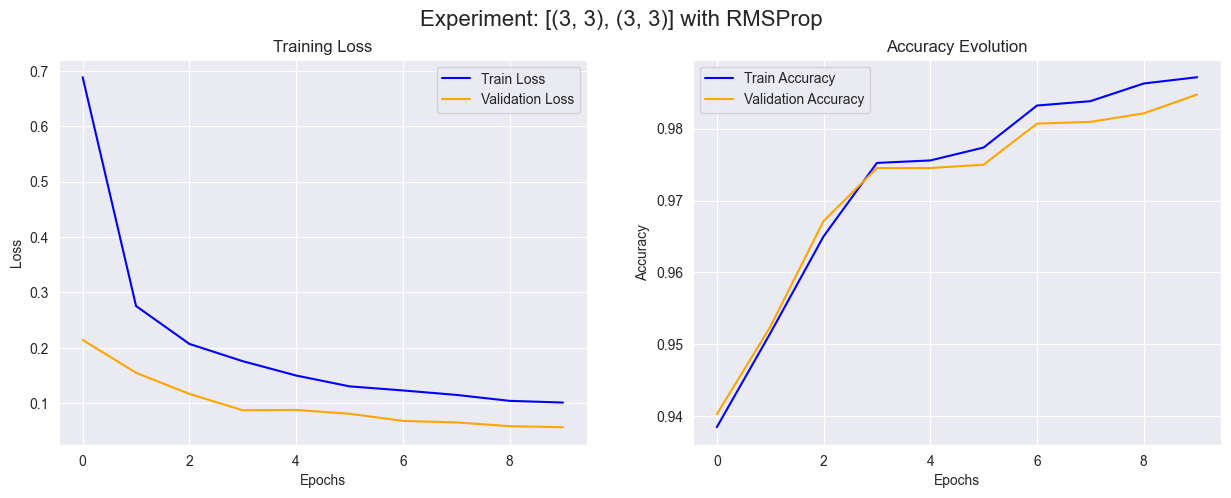

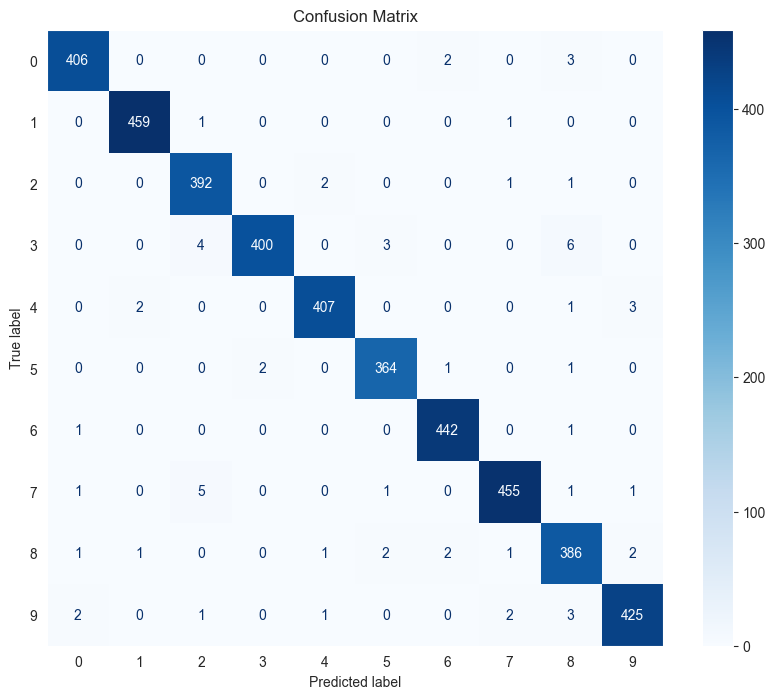

Experiment with kernel [(7, 1), (1, 7)] and optimizer: RMSProp 
Epoch [1/10]
  Train -> Loss: 0.6855 | Accuracy: 0.9151 | Precision: 0.9211 | Recall: 0.9138 | F1: 0.9149
  Valid -> Loss: 0.2904 | Accuracy: 0.9188 | Precision: 0.9246 | Recall: 0.9176 | F1: 0.9186
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.3249 | Accuracy: 0.9524 | Precision: 0.9529 | Recall: 0.9523 | F1: 0.9523
  Valid -> Loss: 0.1799 | Accuracy: 0.9548 | Precision: 0.9548 | Recall: 0.9544 | F1: 0.9542
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.2413 | Accuracy: 0.9627 | Precision: 0.9625 | Recall: 0.9627 | F1: 0.9624
  Valid -> Loss: 0.1289 | Accuracy: 0.9633 | Precision: 0.9628 | Recall: 0.9632 | F1: 0.9628
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.1998

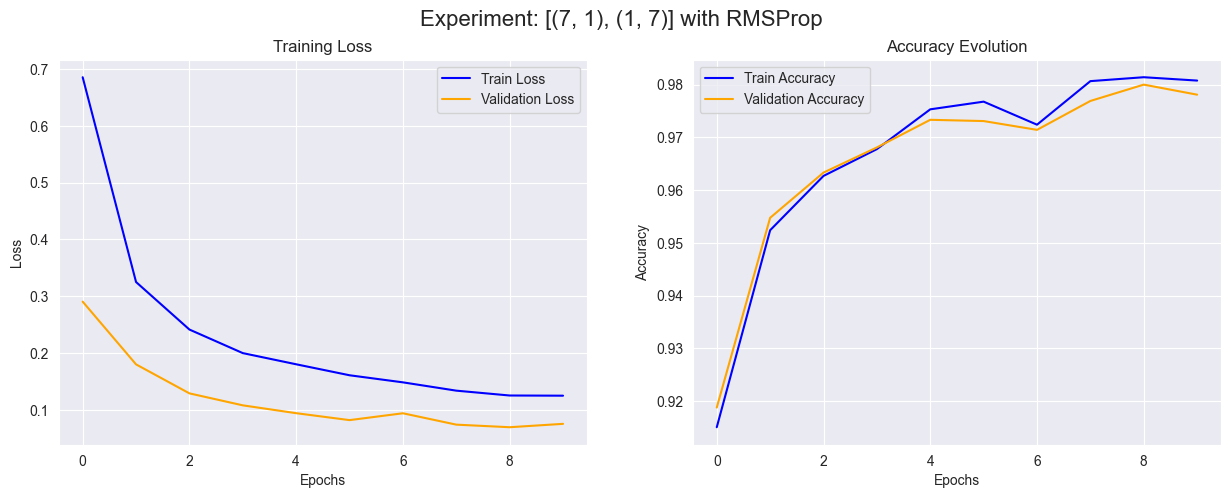

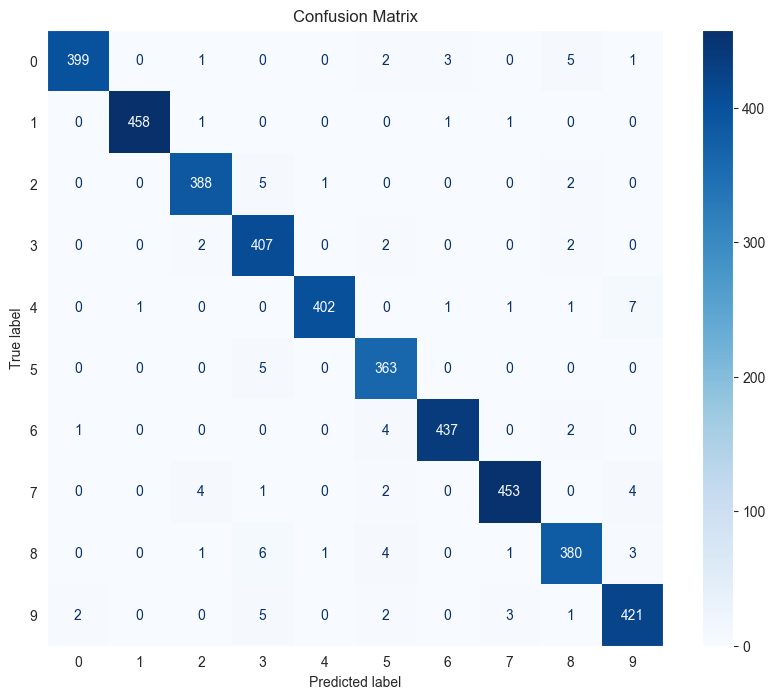

Experiment with kernel [(7, 7), (5, 5)] and optimizer: RMSProp 
Epoch [1/10]
  Train -> Loss: 0.4798 | Accuracy: 0.9565 | Precision: 0.9580 | Recall: 0.9558 | F1: 0.9564
  Valid -> Loss: 0.1522 | Accuracy: 0.9567 | Precision: 0.9575 | Recall: 0.9557 | F1: 0.9560
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.1772 | Accuracy: 0.9690 | Precision: 0.9697 | Recall: 0.9687 | F1: 0.9689
  Valid -> Loss: 0.1082 | Accuracy: 0.9676 | Precision: 0.9681 | Recall: 0.9668 | F1: 0.9670
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.1357 | Accuracy: 0.9794 | Precision: 0.9793 | Recall: 0.9794 | F1: 0.9794
  Valid -> Loss: 0.0733 | Accuracy: 0.9779 | Precision: 0.9775 | Recall: 0.9775 | F1: 0.9775
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.1167

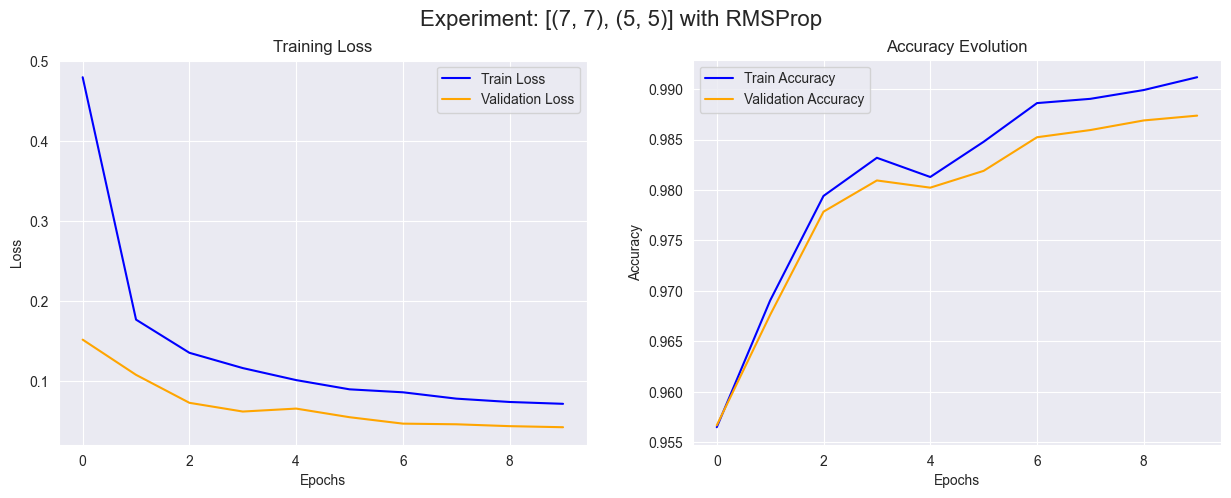

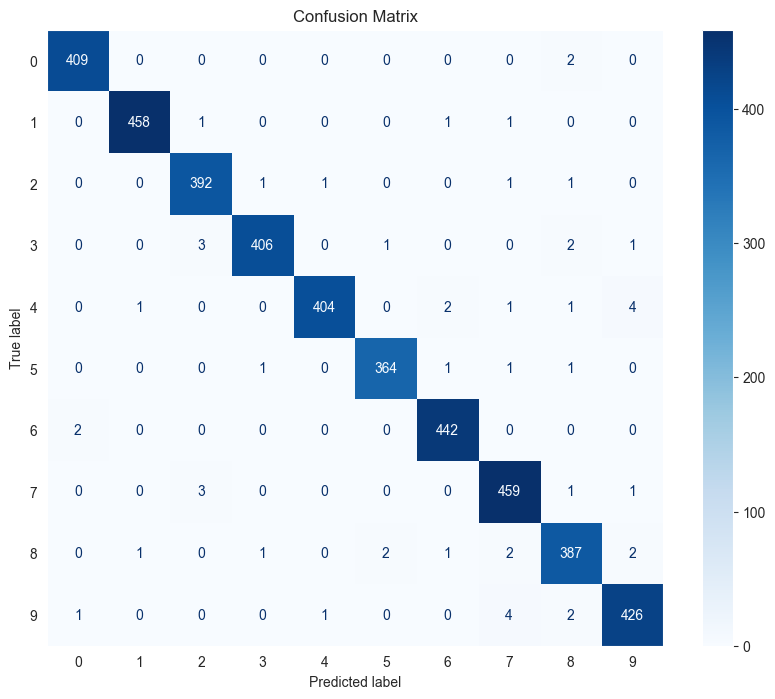

Experiment with kernel [(3, 1), (1, 3)] and optimizer: RMSProp 
Epoch [1/10]
  Train -> Loss: 0.8712 | Accuracy: 0.8658 | Precision: 0.8836 | Recall: 0.8657 | F1: 0.8662
  Valid -> Loss: 0.4183 | Accuracy: 0.8714 | Precision: 0.8855 | Recall: 0.8693 | F1: 0.8700
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.4468 | Accuracy: 0.9155 | Precision: 0.9176 | Recall: 0.9145 | F1: 0.9134
  Valid -> Loss: 0.2989 | Accuracy: 0.9226 | Precision: 0.9241 | Recall: 0.9210 | F1: 0.9202
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.3549 | Accuracy: 0.9358 | Precision: 0.9389 | Recall: 0.9350 | F1: 0.9356
  Valid -> Loss: 0.2227 | Accuracy: 0.9367 | Precision: 0.9383 | Recall: 0.9353 | F1: 0.9355
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.2997

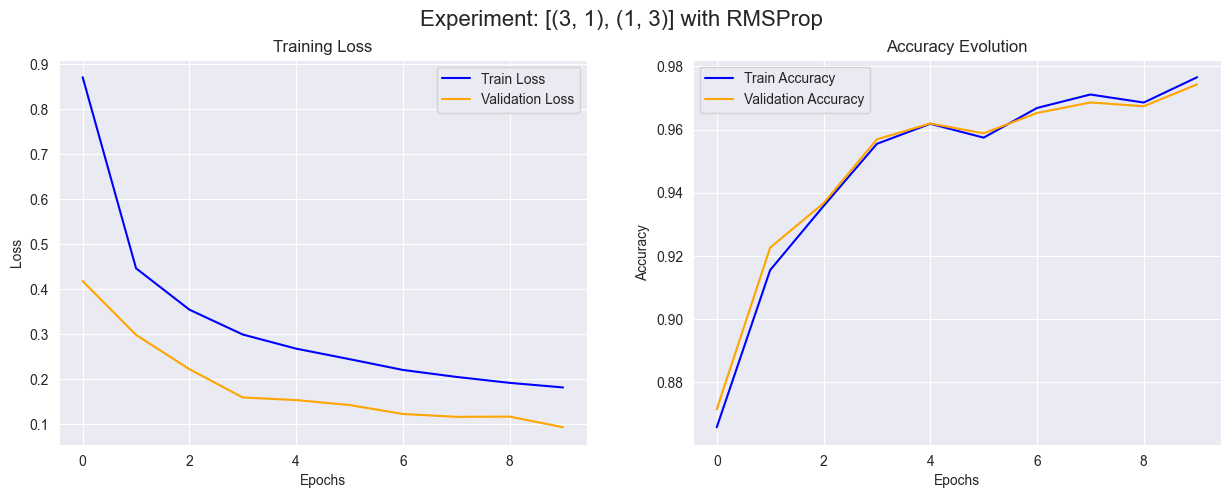

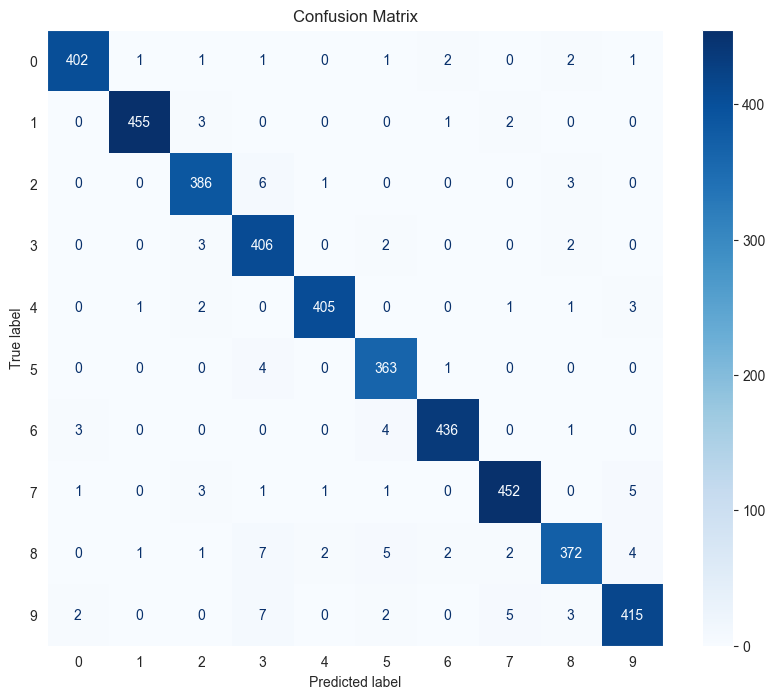

In [18]:
for kernel in configs:
    run_experiment(kernel, "RMSProp", 10, train_loader_plain, val_loader)

Experiment with kernel [(5, 5), (3, 3)] and optimizer: SGD 
Epoch [1/10]
  Train -> Loss: 1.4307 | Accuracy: 0.8746 | Precision: 0.8789 | Recall: 0.8716 | F1: 0.8728
  Valid -> Loss: 0.4257 | Accuracy: 0.8831 | Precision: 0.8875 | Recall: 0.8804 | F1: 0.8816
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.5010 | Accuracy: 0.9321 | Precision: 0.9329 | Recall: 0.9311 | F1: 0.9314
  Valid -> Loss: 0.2344 | Accuracy: 0.9357 | Precision: 0.9360 | Recall: 0.9347 | F1: 0.9350
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.3340 | Accuracy: 0.9548 | Precision: 0.9553 | Recall: 0.9544 | F1: 0.9546
  Valid -> Loss: 0.1548 | Accuracy: 0.9564 | Precision: 0.9562 | Recall: 0.9558 | F1: 0.9559
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.2450 | A

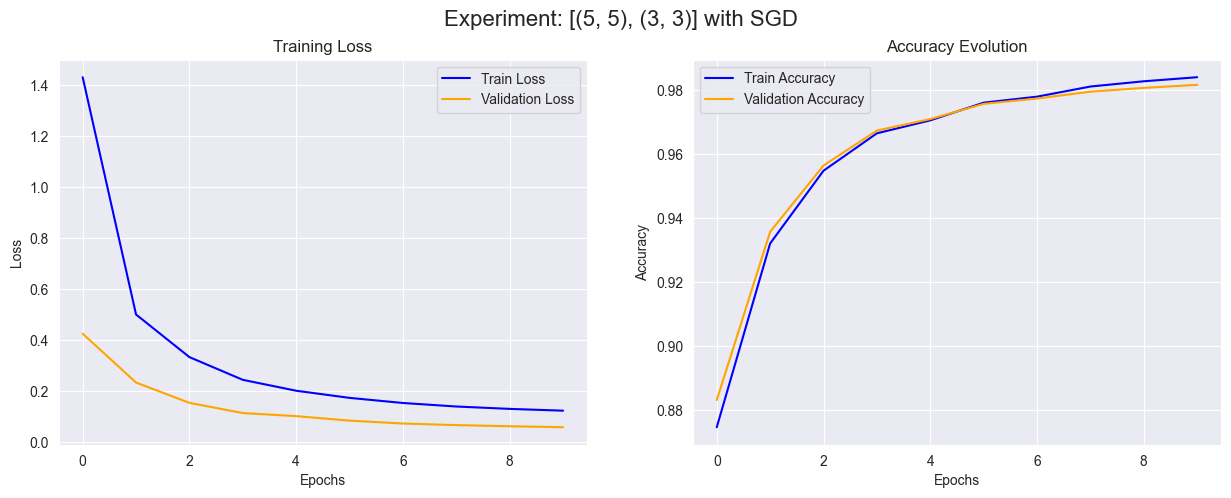

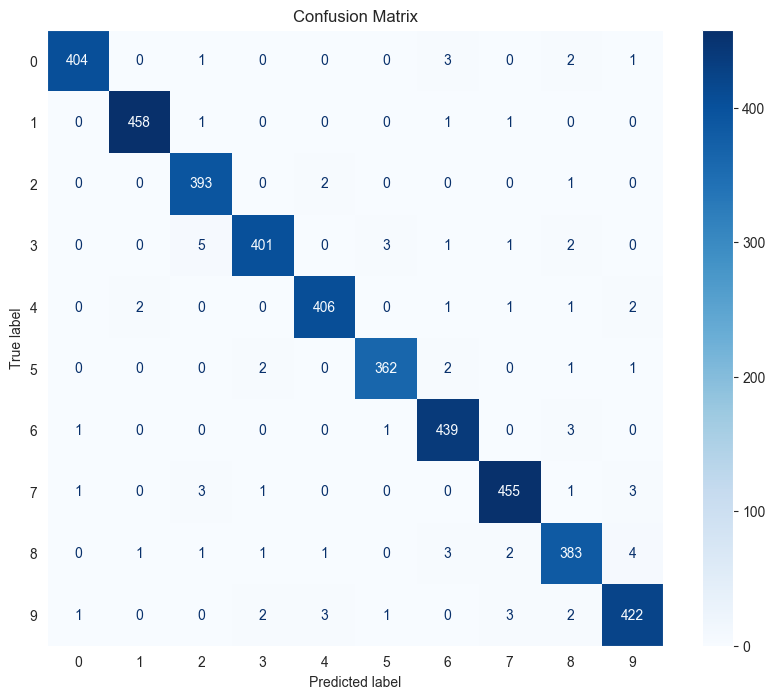

Experiment with kernel [(3, 3), (3, 3)] and optimizer: SGD 
Epoch [1/10]
  Train -> Loss: 1.6409 | Accuracy: 0.8680 | Precision: 0.8703 | Recall: 0.8654 | F1: 0.8654
  Valid -> Loss: 0.4704 | Accuracy: 0.8819 | Precision: 0.8841 | Recall: 0.8788 | F1: 0.8796
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.5793 | Accuracy: 0.9194 | Precision: 0.9210 | Recall: 0.9185 | F1: 0.9187
  Valid -> Loss: 0.2771 | Accuracy: 0.9233 | Precision: 0.9244 | Recall: 0.9224 | F1: 0.9227
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.4078 | Accuracy: 0.9456 | Precision: 0.9454 | Recall: 0.9453 | F1: 0.9451
  Valid -> Loss: 0.2094 | Accuracy: 0.9462 | Precision: 0.9456 | Recall: 0.9457 | F1: 0.9454
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.3190 | A

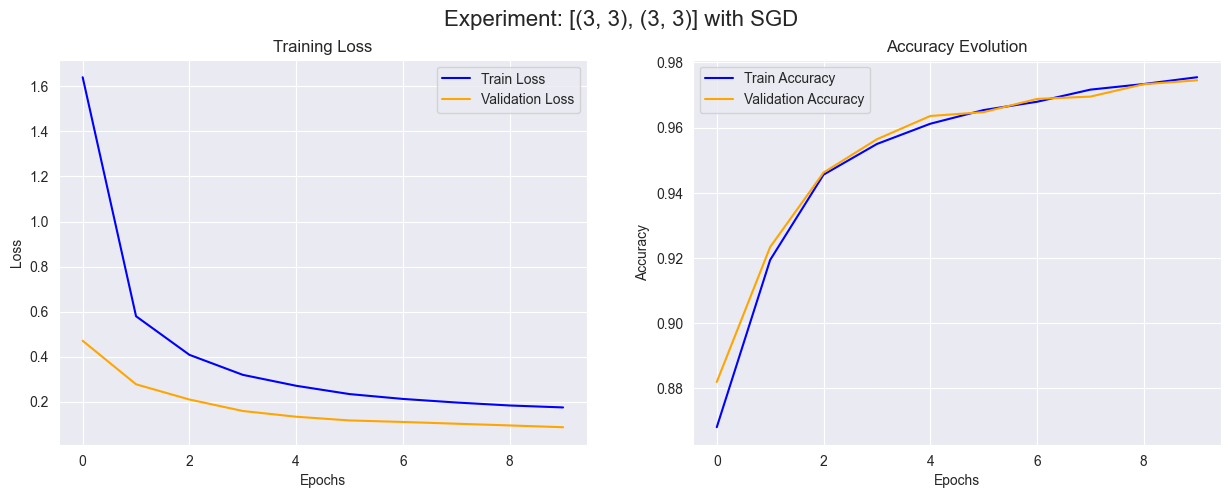

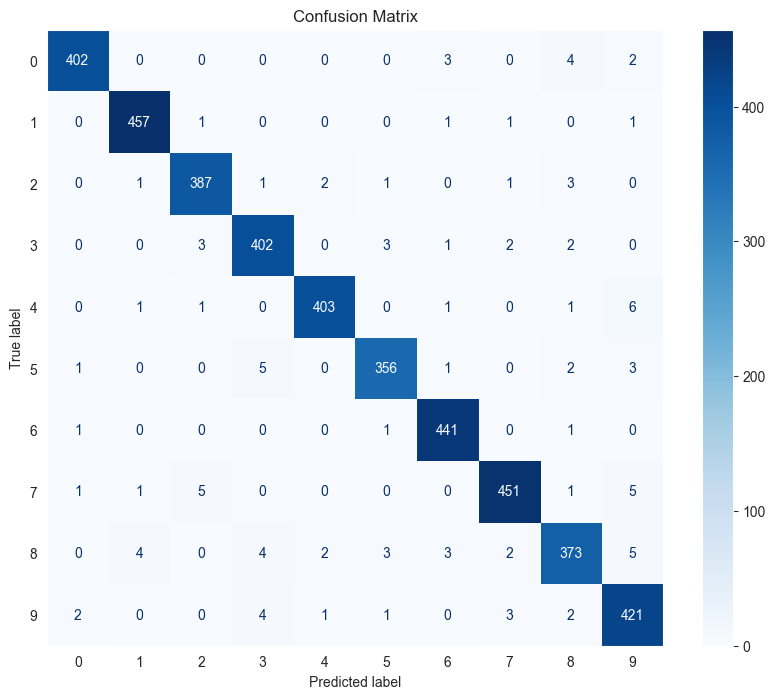

Experiment with kernel [(7, 1), (1, 7)] and optimizer: SGD 
Epoch [1/10]
  Train -> Loss: 1.6166 | Accuracy: 0.8428 | Precision: 0.8508 | Recall: 0.8386 | F1: 0.8377
  Valid -> Loss: 0.5360 | Accuracy: 0.8438 | Precision: 0.8525 | Recall: 0.8387 | F1: 0.8383
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.5994 | Accuracy: 0.9163 | Precision: 0.9164 | Recall: 0.9153 | F1: 0.9155
  Valid -> Loss: 0.2980 | Accuracy: 0.9238 | Precision: 0.9236 | Recall: 0.9226 | F1: 0.9228
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.4164 | Accuracy: 0.9356 | Precision: 0.9373 | Recall: 0.9350 | F1: 0.9355
  Valid -> Loss: 0.2190 | Accuracy: 0.9374 | Precision: 0.9383 | Recall: 0.9368 | F1: 0.9371
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.3396 | A

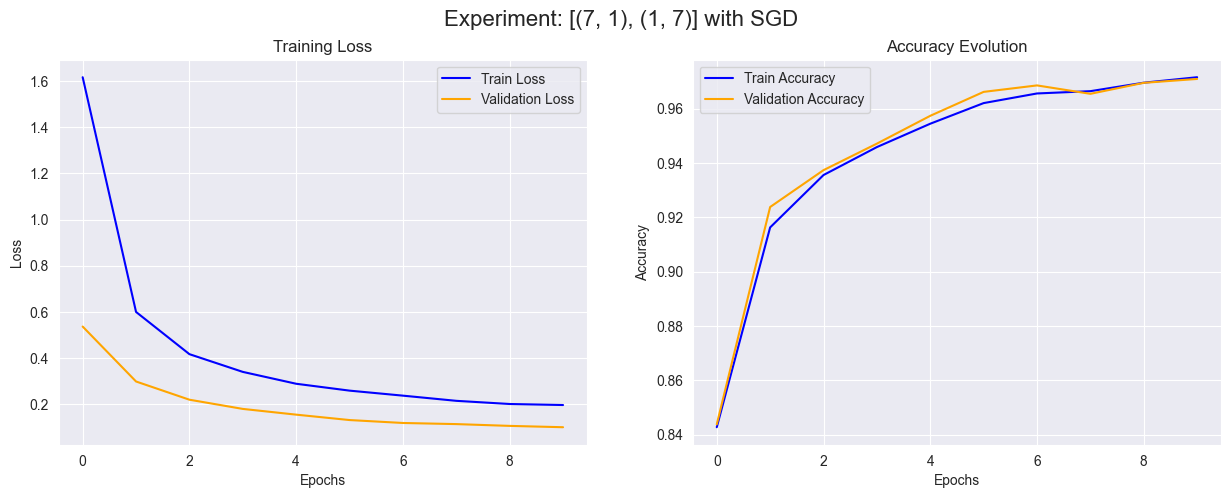

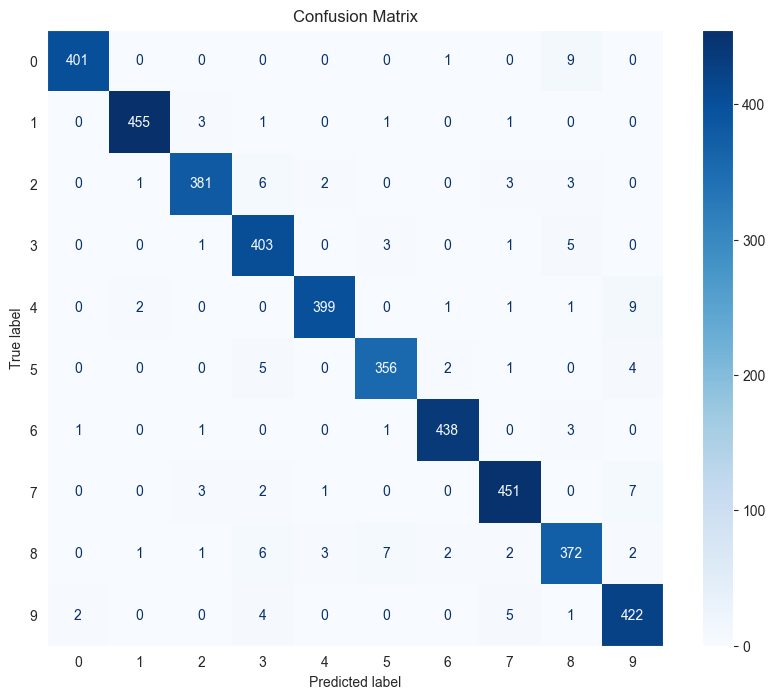

Experiment with kernel [(7, 7), (5, 5)] and optimizer: SGD 
Epoch [1/10]
  Train -> Loss: 1.6047 | Accuracy: 0.8661 | Precision: 0.8687 | Recall: 0.8647 | F1: 0.8636
  Valid -> Loss: 0.4287 | Accuracy: 0.8695 | Precision: 0.8724 | Recall: 0.8694 | F1: 0.8678
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.4270 | Accuracy: 0.9440 | Precision: 0.9439 | Recall: 0.9439 | F1: 0.9436
  Valid -> Loss: 0.1823 | Accuracy: 0.9483 | Precision: 0.9483 | Recall: 0.9477 | F1: 0.9477
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.2666 | Accuracy: 0.9602 | Precision: 0.9603 | Recall: 0.9601 | F1: 0.9600
  Valid -> Loss: 0.1351 | Accuracy: 0.9621 | Precision: 0.9620 | Recall: 0.9615 | F1: 0.9615
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.2146 | A

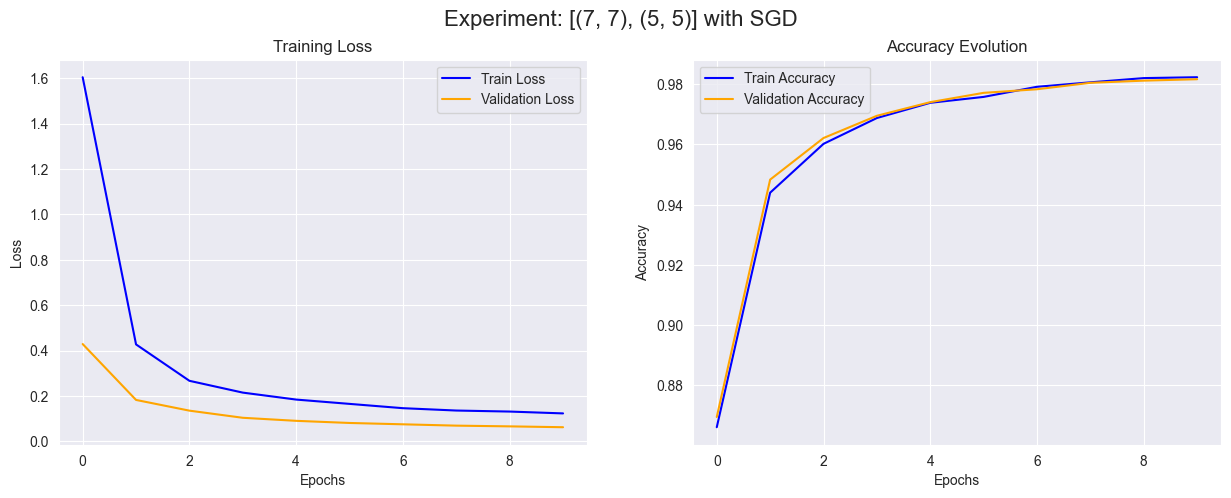

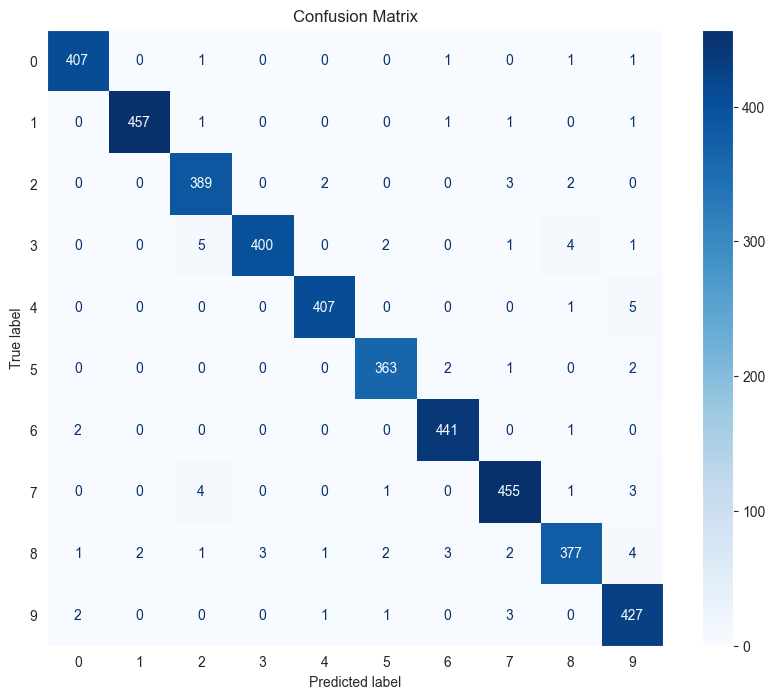

Experiment with kernel [(3, 1), (1, 3)] and optimizer: SGD 


D:\3Course\SixthSemester\DeepLearning\Labs\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Epoch [1/10]
  Train -> Loss: 2.2650 | Accuracy: 0.4939 | Precision: 0.7294 | Recall: 0.4817 | F1: 0.4406
  Valid -> Loss: 2.0414 | Accuracy: 0.5014 | Precision: 0.6506 | Recall: 0.4871 | F1: 0.4509
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.9956 | Accuracy: 0.8726 | Precision: 0.8717 | Recall: 0.8704 | F1: 0.8699
  Valid -> Loss: 0.4909 | Accuracy: 0.8802 | Precision: 0.8801 | Recall: 0.8774 | F1: 0.8777
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.6045 | Accuracy: 0.8984 | Precision: 0.9006 | Recall: 0.8968 | F1: 0.8973
  Valid -> Loss: 0.3633 | Accuracy: 0.9019 | Precision: 0.9038 | Recall: 0.8996 | F1: 0.9004
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.4777 | Accuracy: 0.9206 | Precision: 0.9212 | Recall: 0.9192 | F1: 0

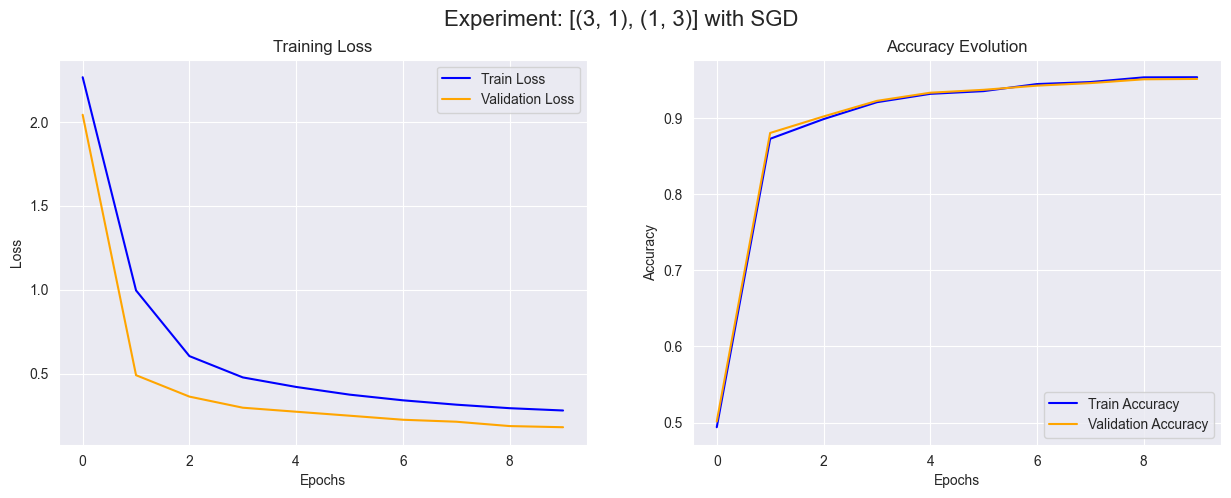

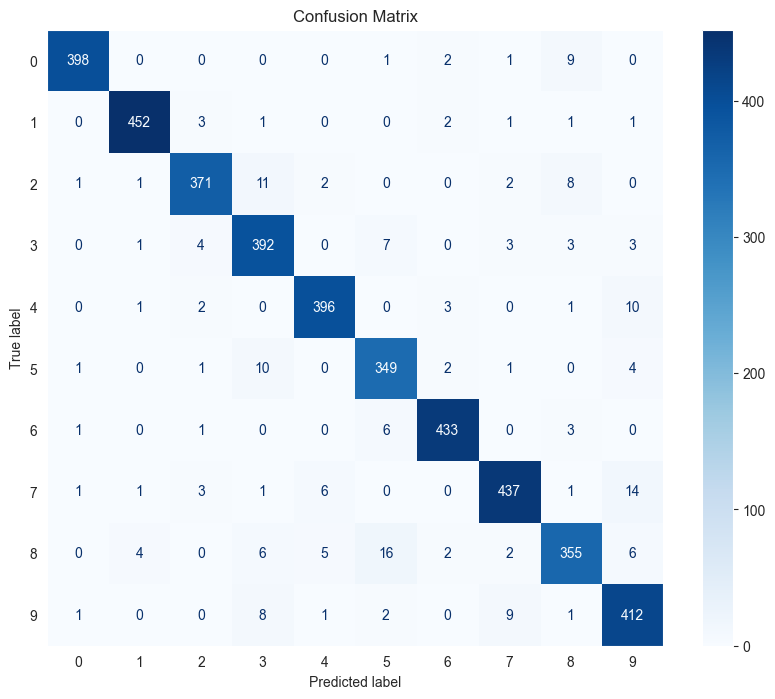

In [19]:
for kernel in configs:
    run_experiment(kernel, "SGD", 10, train_loader_plain, val_loader)

Experiment with deep network with kernel [(5, 5), (3, 3), (3, 3)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 1.0409 | Accuracy: 0.9354 | Precision: 0.9357 | Recall: 0.9350 | F1: 0.9352
  Valid -> Loss: 0.2307 | Accuracy: 0.9331 | Precision: 0.9333 | Recall: 0.9325 | F1: 0.9327
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.3304 | Accuracy: 0.9564 | Precision: 0.9567 | Recall: 0.9561 | F1: 0.9561
  Valid -> Loss: 0.1492 | Accuracy: 0.9548 | Precision: 0.9546 | Recall: 0.9539 | F1: 0.9540
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.2468 | Accuracy: 0.9643 | Precision: 0.9648 | Recall: 0.9639 | F1: 0.9642
  Valid -> Loss: 0.1144 | Accuracy: 0.9643 | Precision: 0.9648 | Recall: 0.9634 | F1: 0.9639
----------------------------------------------------------------------------------------------------
Epoch [4/10]


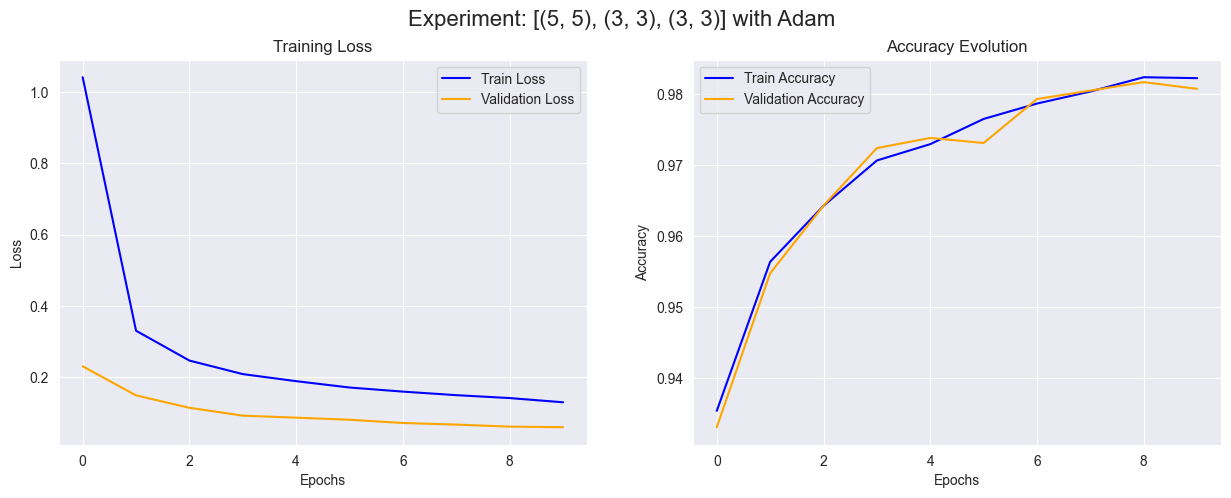

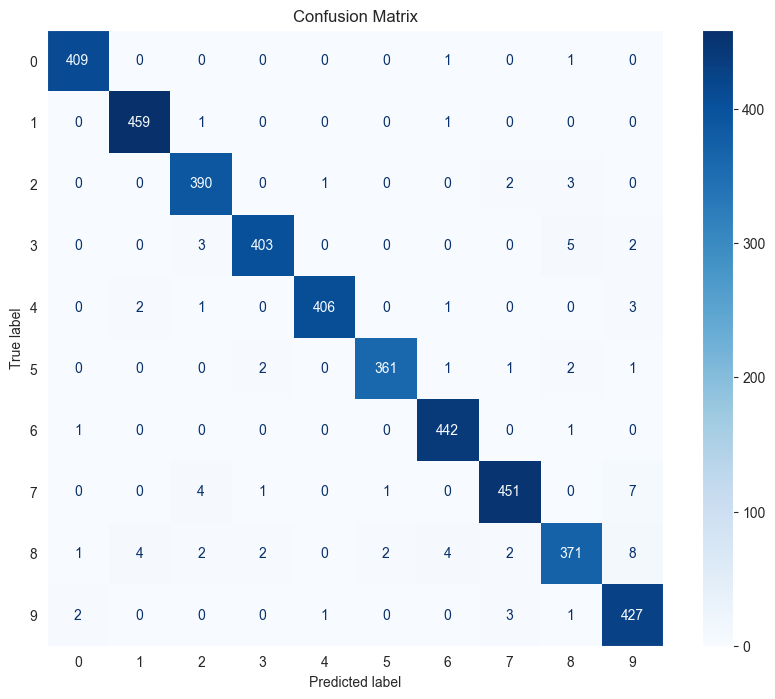

Experiment with deep network with kernel [(3, 3), (3, 3), (3, 3)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 1.1476 | Accuracy: 0.9103 | Precision: 0.9145 | Recall: 0.9090 | F1: 0.9092
  Valid -> Loss: 0.3092 | Accuracy: 0.9152 | Precision: 0.9185 | Recall: 0.9133 | F1: 0.9137
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.3835 | Accuracy: 0.9509 | Precision: 0.9517 | Recall: 0.9506 | F1: 0.9509
  Valid -> Loss: 0.1673 | Accuracy: 0.9502 | Precision: 0.9508 | Recall: 0.9498 | F1: 0.9500
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.2794 | Accuracy: 0.9630 | Precision: 0.9632 | Recall: 0.9630 | F1: 0.9630
  Valid -> Loss: 0.1238 | Accuracy: 0.9598 | Precision: 0.9594 | Recall: 0.9593 | F1: 0.9593
----------------------------------------------------------------------------------------------------
Epoch [4/10]


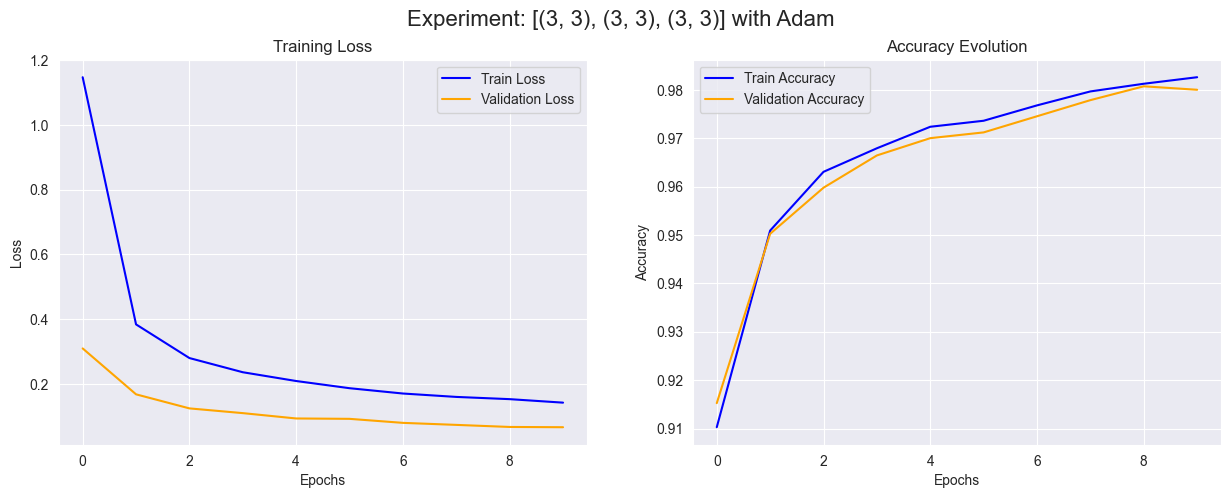

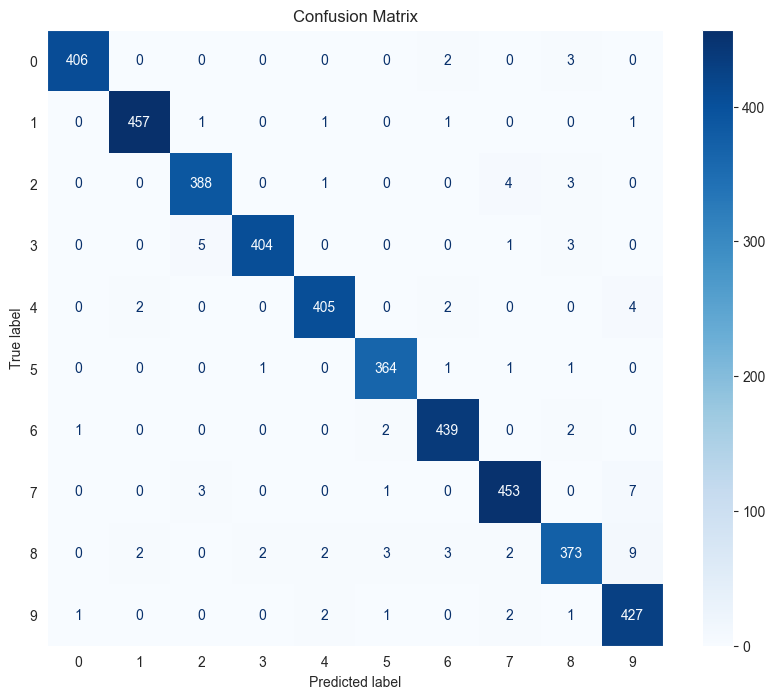

Experiment with deep network with kernel [(7, 1), (1, 7), (3, 3)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 1.3729 | Accuracy: 0.8759 | Precision: 0.8815 | Recall: 0.8737 | F1: 0.8748
  Valid -> Loss: 0.4439 | Accuracy: 0.8810 | Precision: 0.8867 | Recall: 0.8781 | F1: 0.8799
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.4828 | Accuracy: 0.9370 | Precision: 0.9381 | Recall: 0.9365 | F1: 0.9368
  Valid -> Loss: 0.2115 | Accuracy: 0.9398 | Precision: 0.9403 | Recall: 0.9392 | F1: 0.9394
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.3339 | Accuracy: 0.9539 | Precision: 0.9541 | Recall: 0.9537 | F1: 0.9538
  Valid -> Loss: 0.1548 | Accuracy: 0.9548 | Precision: 0.9545 | Recall: 0.9542 | F1: 0.9543
----------------------------------------------------------------------------------------------------
Epoch [4/10]


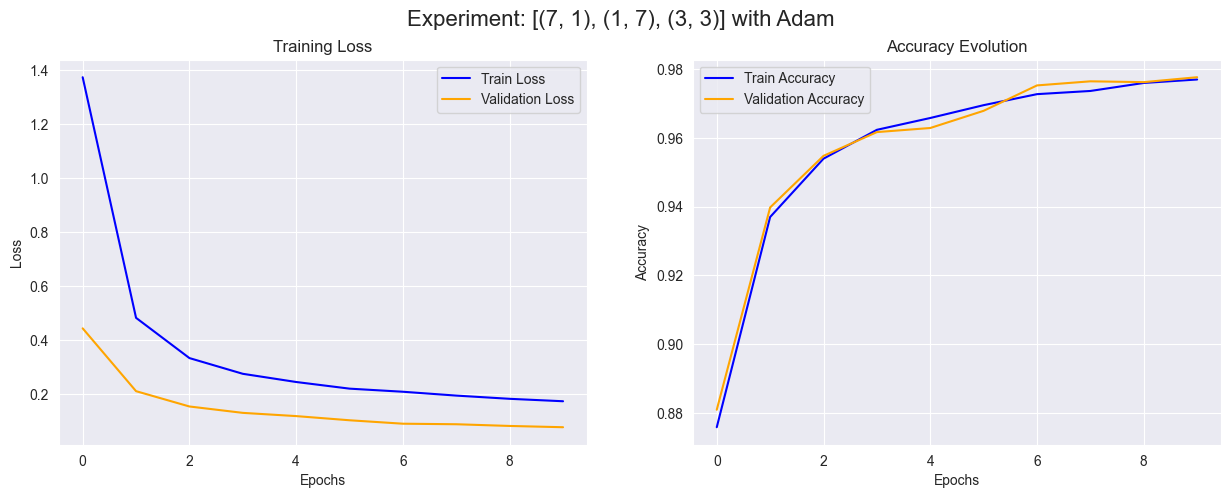

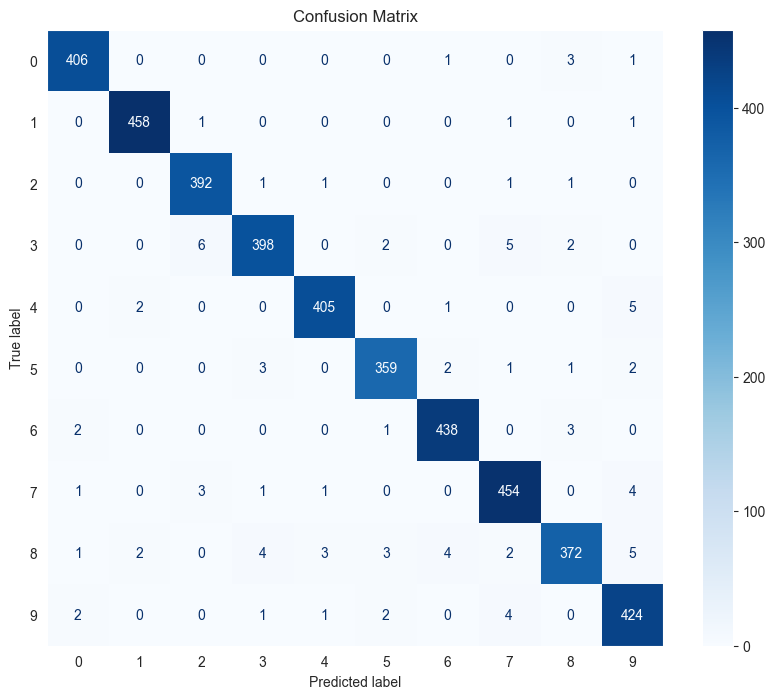

In [20]:
for kernel in deep_configs:
    run_experiment_with_deep_network(kernel, "Adam", 10, train_loader_plain, val_loader)

Experiment with LeNet-5 and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 0.7023 | Accuracy: 0.9174 | Precision: 0.9169 | Recall: 0.9164 | F1: 0.9165
  Valid -> Loss: 0.2735 | Accuracy: 0.9207 | Precision: 0.9206 | Recall: 0.9191 | F1: 0.9196
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.2244 | Accuracy: 0.9475 | Precision: 0.9479 | Recall: 0.9474 | F1: 0.9474
  Valid -> Loss: 0.1826 | Accuracy: 0.9488 | Precision: 0.9489 | Recall: 0.9486 | F1: 0.9484
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.1469 | Accuracy: 0.9644 | Precision: 0.9644 | Recall: 0.9640 | F1: 0.9641
  Valid -> Loss: 0.1268 | Accuracy: 0.9617 | Precision: 0.9616 | Recall: 0.9611 | F1: 0.9613
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.1088 | Accuracy: 0.9737

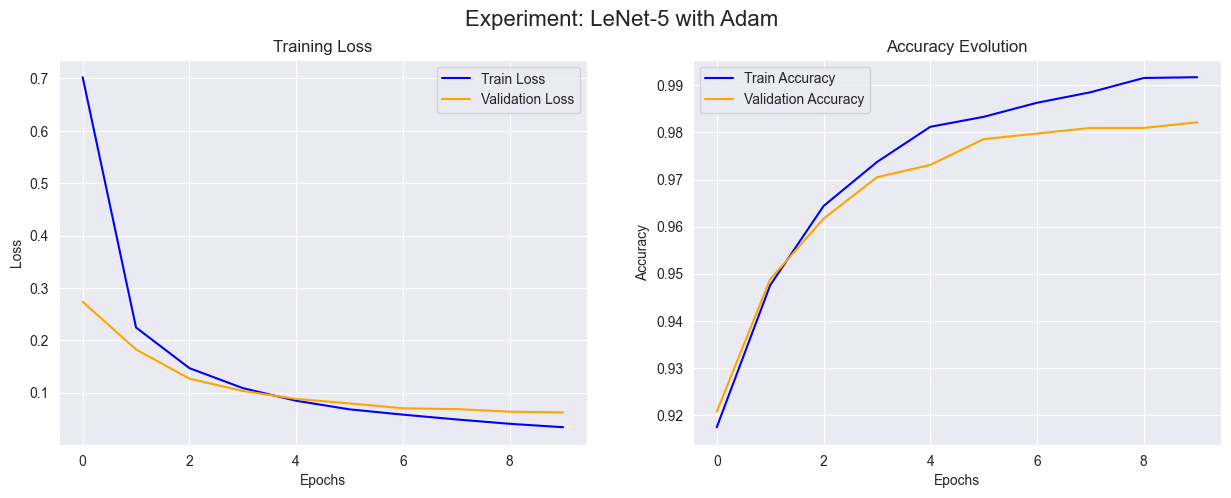

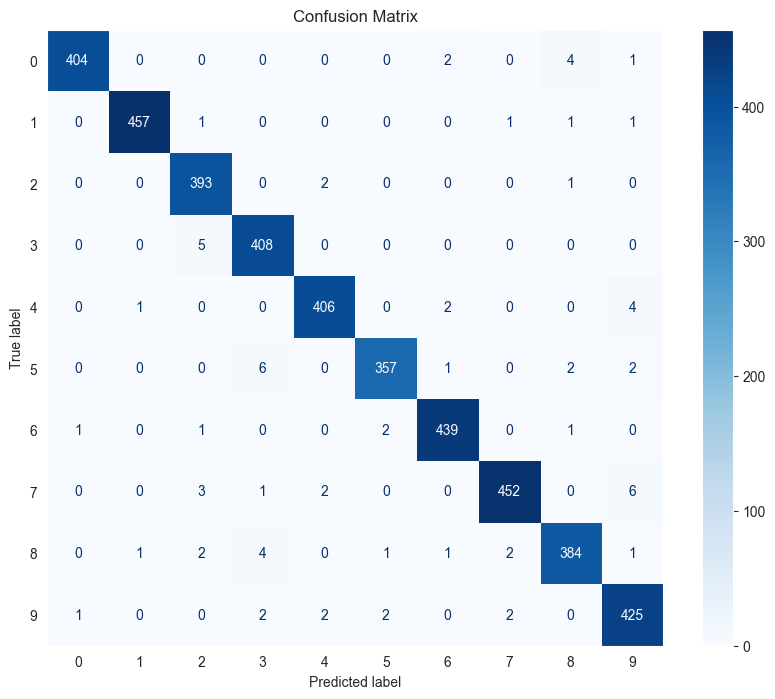

{'train_loss': [0.7022673620989448,
  0.22440046954311824,
  0.14685349168844128,
  0.10876346838439961,
  0.0845916458944741,
  0.06816832977347076,
  0.05808868106013458,
  0.04896307633699555,
  0.040642777365926454,
  0.03407287416906145],
 'train_accuracy': [0.9174074074074074,
  0.9475396825396826,
  0.9643650793650793,
  0.9737037037037037,
  0.9811904761904762,
  0.9833068783068784,
  0.9862962962962963,
  0.9885185185185185,
  0.9915608465608465,
  0.9917195767195767],
 'val_precision': [0.9205557681942163,
  0.9489169675158446,
  0.9615774598054058,
  0.9702752527307957,
  0.9725546083150555,
  0.9780482049091954,
  0.979562780864182,
  0.9806668840090305,
  0.9805682066944275,
  0.9820417104617007],
 'val_recall': [0.9190710586184648,
  0.9485983683892302,
  0.9610570176653054,
  0.9701710604422848,
  0.9730589555972988,
  0.9786878253361075,
  0.9795617123309098,
  0.9810486117907183,
  0.9809925860237106,
  0.981960514052686],
 'val_accuracy': [0.9207142857142857,
  0.9488

In [21]:
run_experiment_with_lenet5("Adam", 10, train_loader_plain, val_loader)

Experiment with LeNet-5 and optimizer: RMSProp 
Epoch [1/10]
  Train -> Loss: 0.4036 | Accuracy: 0.9289 | Precision: 0.9306 | Recall: 0.9275 | F1: 0.9282
  Valid -> Loss: 0.2314 | Accuracy: 0.9343 | Precision: 0.9353 | Recall: 0.9326 | F1: 0.9333
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.1749 | Accuracy: 0.9562 | Precision: 0.9559 | Recall: 0.9563 | F1: 0.9558
  Valid -> Loss: 0.1509 | Accuracy: 0.9588 | Precision: 0.9585 | Recall: 0.9587 | F1: 0.9582
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.1211 | Accuracy: 0.9575 | Precision: 0.9589 | Recall: 0.9569 | F1: 0.9570
  Valid -> Loss: 0.1534 | Accuracy: 0.9555 | Precision: 0.9563 | Recall: 0.9547 | F1: 0.9546
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.0918 | Accuracy: 0.9

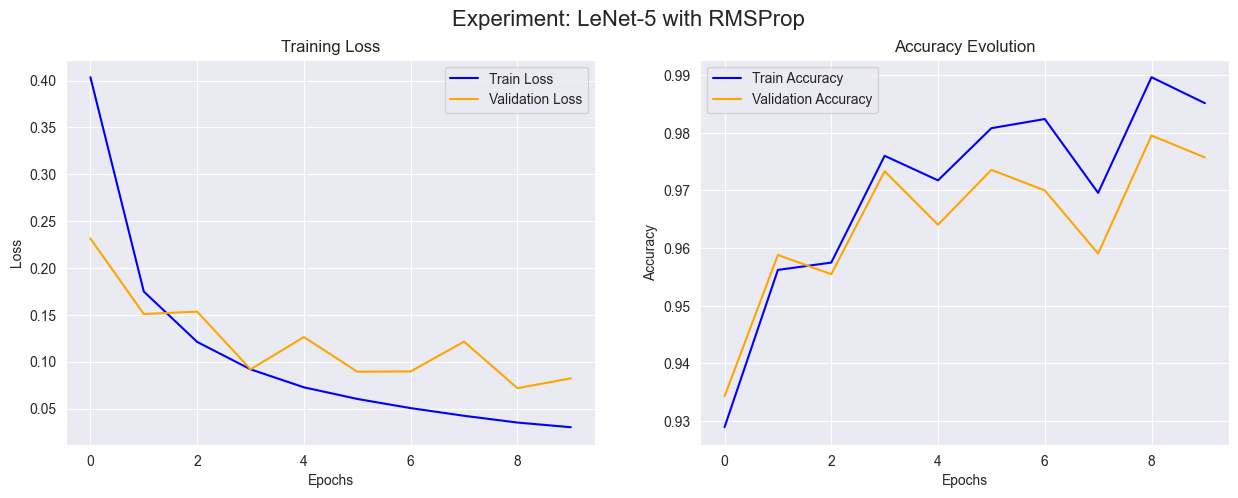

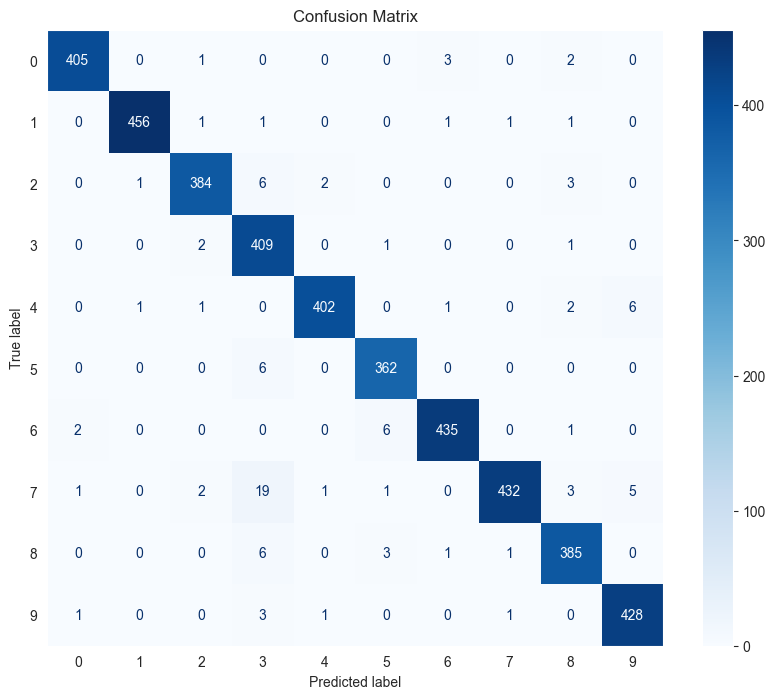

{'train_loss': [0.4036221981636788,
  0.17486199055259166,
  0.12108763814658711,
  0.09182700058935504,
  0.07261950128074539,
  0.0602044719026277,
  0.050416578716402385,
  0.04223494849314815,
  0.035010126260060226,
  0.030027555099590438],
 'train_accuracy': [0.928941798941799,
  0.9562169312169312,
  0.9574867724867725,
  0.976005291005291,
  0.9717460317460317,
  0.9807936507936508,
  0.9823809523809524,
  0.9695767195767195,
  0.9896296296296296,
  0.9851322751322751],
 'val_precision': [0.9353312399212814,
  0.958538903463998,
  0.9562889205036909,
  0.9735883937660423,
  0.9655626816721034,
  0.9739694241125584,
  0.9699631732383803,
  0.9628621013097061,
  0.9794377438353197,
  0.975927422079946],
 'val_recall': [0.9325801586256975,
  0.9586617259272335,
  0.9547127383984491,
  0.9729834232218014,
  0.9642126630875497,
  0.973205421693795,
  0.9703225498929688,
  0.9574433002359761,
  0.9791992981423296,
  0.9760790032067229],
 'val_accuracy': [0.9342857142857143,
  0.95880

In [22]:
run_experiment_with_lenet5("RMSProp", 10, train_loader_plain, val_loader)

Experiment with LeNet-5 and optimizer: SGD 
Epoch [1/10]
  Train -> Loss: 1.8208 | Accuracy: 0.8087 | Precision: 0.8076 | Recall: 0.8048 | F1: 0.8037
  Valid -> Loss: 0.7087 | Accuracy: 0.8157 | Precision: 0.8140 | Recall: 0.8110 | F1: 0.8108
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.4714 | Accuracy: 0.9007 | Precision: 0.8995 | Recall: 0.8994 | F1: 0.8992
  Valid -> Loss: 0.3453 | Accuracy: 0.9052 | Precision: 0.9044 | Recall: 0.9036 | F1: 0.9038
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.3060 | Accuracy: 0.9222 | Precision: 0.9215 | Recall: 0.9213 | F1: 0.9212
  Valid -> Loss: 0.2656 | Accuracy: 0.9240 | Precision: 0.9231 | Recall: 0.9227 | F1: 0.9228
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.2389 | Accuracy: 0.9368 

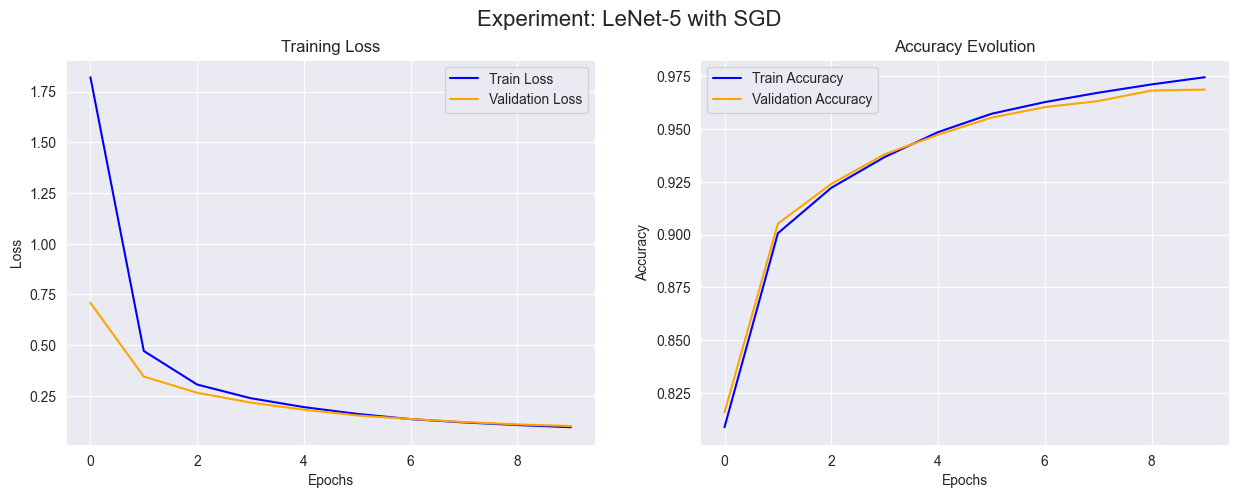

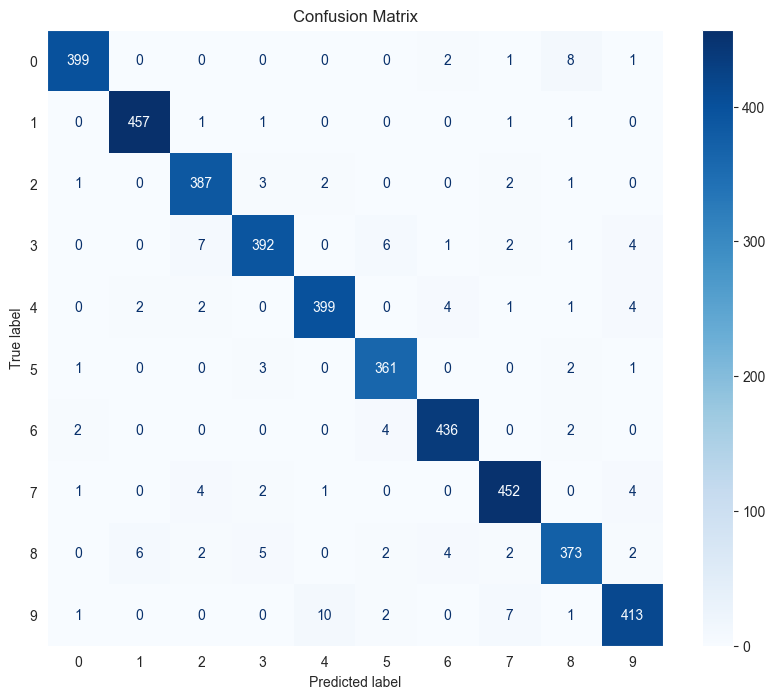

{'train_loss': [1.8207606355610646,
  0.47142325086813225,
  0.30604914409157474,
  0.23890664457882704,
  0.19481560573177903,
  0.1614076082447642,
  0.1355907749139557,
  0.11944288446715004,
  0.10641521186028656,
  0.09574419681571032],
 'train_accuracy': [0.8086772486772487,
  0.9006613756613756,
  0.9221957671957672,
  0.9367989417989419,
  0.9486243386243386,
  0.9573015873015873,
  0.9628571428571429,
  0.9673015873015873,
  0.9712433862433862,
  0.9746560846560847],
 'val_precision': [0.8139865161927776,
  0.9044453119331266,
  0.9231458493189628,
  0.9377071942009548,
  0.9469021843763621,
  0.9550082597496374,
  0.9600934985213436,
  0.9629880712905466,
  0.9679216441783515,
  0.9685226844654636],
 'val_recall': [0.8109696658495793,
  0.9036104123412102,
  0.9227264313963215,
  0.9372856150888895,
  0.9466172953639951,
  0.95484919587256,
  0.9601452539187093,
  0.9628446197797971,
  0.9682301438000287,
  0.9685283363712067],
 'val_accuracy': [0.8157142857142857,
  0.905238

In [23]:
run_experiment_with_lenet5("SGD", 10, train_loader_plain, val_loader)

Experiment with kernel [(5, 5), (3, 3)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 1.3029 | Accuracy: 0.8356 | Precision: 0.8409 | Recall: 0.8334 | F1: 0.8347
  Valid -> Loss: 0.3462 | Accuracy: 0.9169 | Precision: 0.9220 | Recall: 0.9164 | F1: 0.9174
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.5941 | Accuracy: 0.9216 | Precision: 0.9214 | Recall: 0.9210 | F1: 0.9208
  Valid -> Loss: 0.1653 | Accuracy: 0.9555 | Precision: 0.9557 | Recall: 0.9553 | F1: 0.9553
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.4118 | Accuracy: 0.9434 | Precision: 0.9439 | Recall: 0.9428 | F1: 0.9432
  Valid -> Loss: 0.1176 | Accuracy: 0.9667 | Precision: 0.9666 | Recall: 0.9661 | F1: 0.9663
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.3333 | 

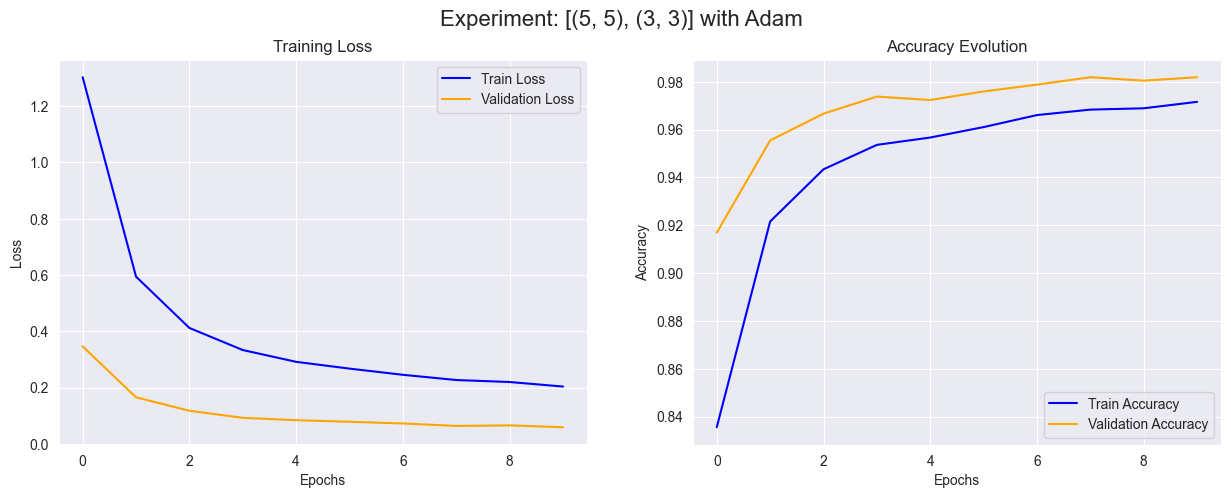

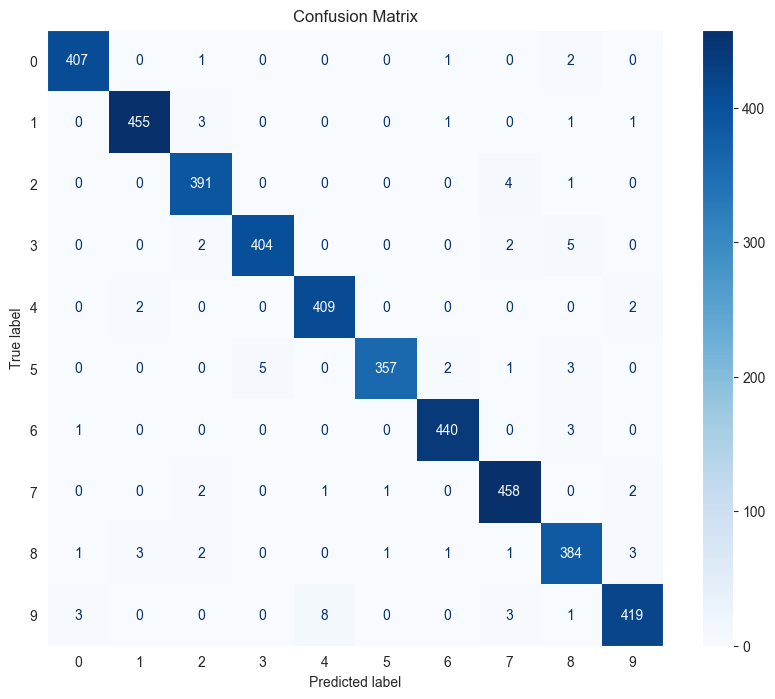

Experiment with kernel [(3, 3), (3, 3)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 1.4273 | Accuracy: 0.8049 | Precision: 0.8086 | Recall: 0.8013 | F1: 0.8014
  Valid -> Loss: 0.3950 | Accuracy: 0.9088 | Precision: 0.9115 | Recall: 0.9062 | F1: 0.9071
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.6548 | Accuracy: 0.9005 | Precision: 0.9021 | Recall: 0.8995 | F1: 0.9000
  Valid -> Loss: 0.1864 | Accuracy: 0.9529 | Precision: 0.9540 | Recall: 0.9525 | F1: 0.9529
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.4735 | Accuracy: 0.9325 | Precision: 0.9329 | Recall: 0.9317 | F1: 0.9320
  Valid -> Loss: 0.1321 | Accuracy: 0.9652 | Precision: 0.9651 | Recall: 0.9648 | F1: 0.9649
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.3856 | 

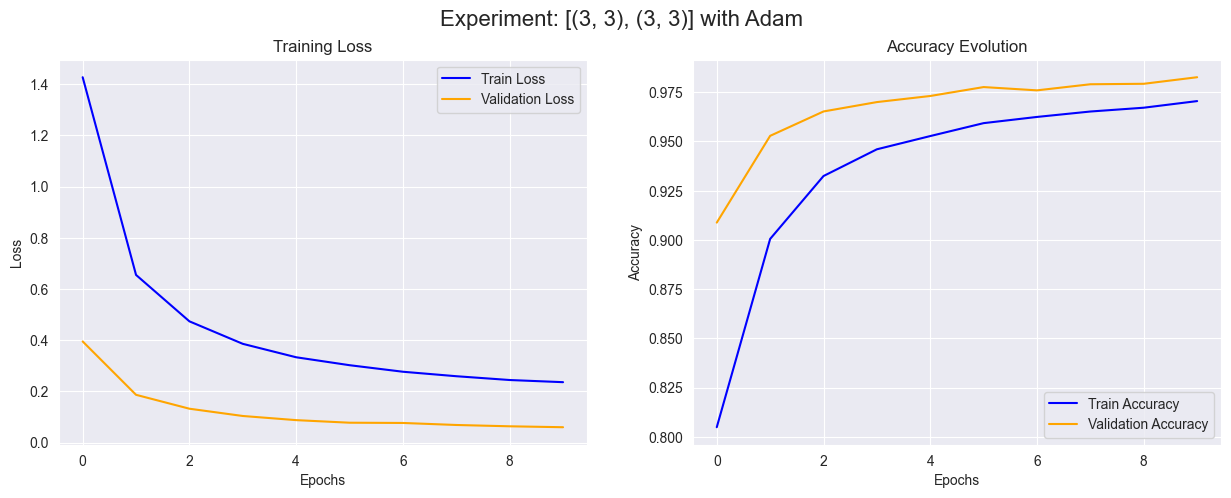

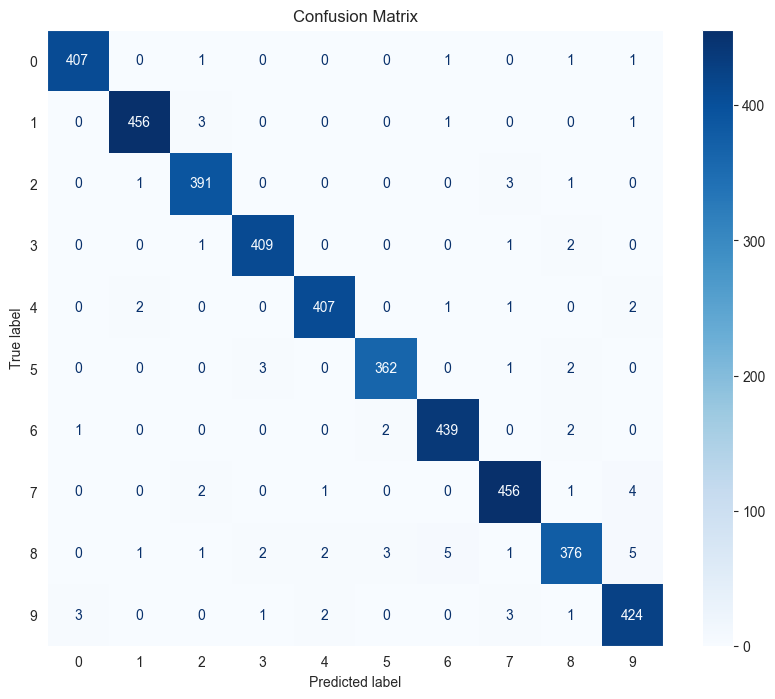

Experiment with kernel [(7, 1), (1, 7)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 1.6760 | Accuracy: 0.6731 | Precision: 0.6814 | Recall: 0.6651 | F1: 0.6608
  Valid -> Loss: 0.7222 | Accuracy: 0.8162 | Precision: 0.8301 | Recall: 0.8084 | F1: 0.8063
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.9807 | Accuracy: 0.8322 | Precision: 0.8369 | Recall: 0.8292 | F1: 0.8308
  Valid -> Loss: 0.3590 | Accuracy: 0.9121 | Precision: 0.9147 | Recall: 0.9104 | F1: 0.9113
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.6919 | Accuracy: 0.8892 | Precision: 0.8924 | Recall: 0.8881 | F1: 0.8888
  Valid -> Loss: 0.2472 | Accuracy: 0.9352 | Precision: 0.9377 | Recall: 0.9354 | F1: 0.9354
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.5629 | 

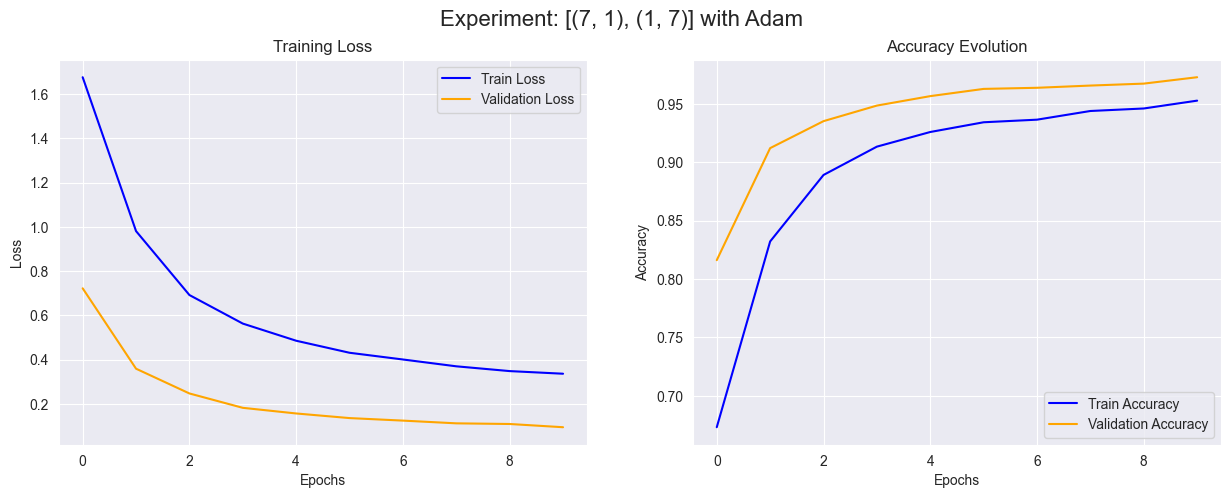

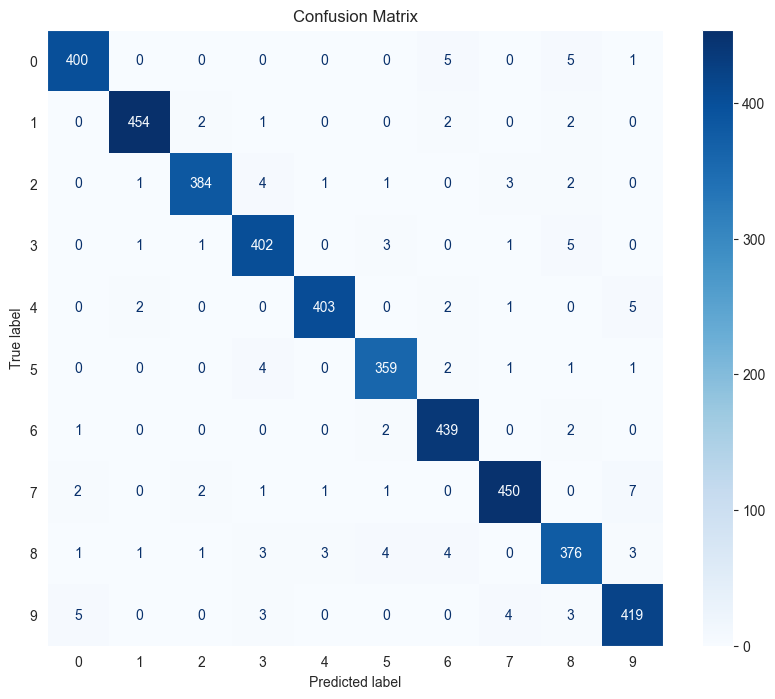

Experiment with kernel [(7, 7), (5, 5)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 1.1310 | Accuracy: 0.8888 | Precision: 0.8882 | Recall: 0.8874 | F1: 0.8874
  Valid -> Loss: 0.2103 | Accuracy: 0.9524 | Precision: 0.9521 | Recall: 0.9522 | F1: 0.9520
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.4445 | Accuracy: 0.9303 | Precision: 0.9308 | Recall: 0.9295 | F1: 0.9297
  Valid -> Loss: 0.1256 | Accuracy: 0.9686 | Precision: 0.9688 | Recall: 0.9678 | F1: 0.9681
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.3252 | Accuracy: 0.9487 | Precision: 0.9491 | Recall: 0.9481 | F1: 0.9485
  Valid -> Loss: 0.0938 | Accuracy: 0.9743 | Precision: 0.9743 | Recall: 0.9737 | F1: 0.9739
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.2717 | 

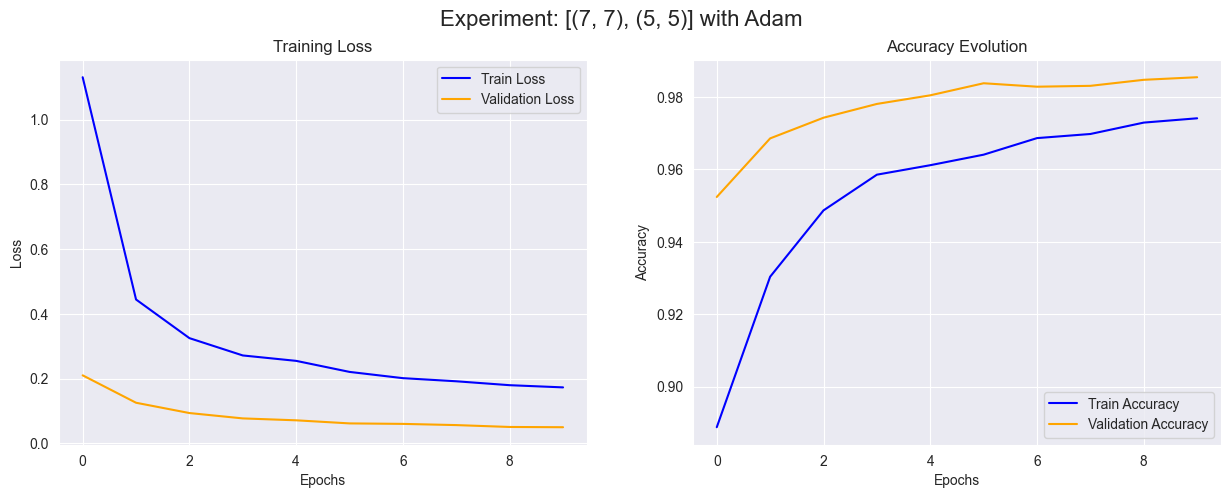

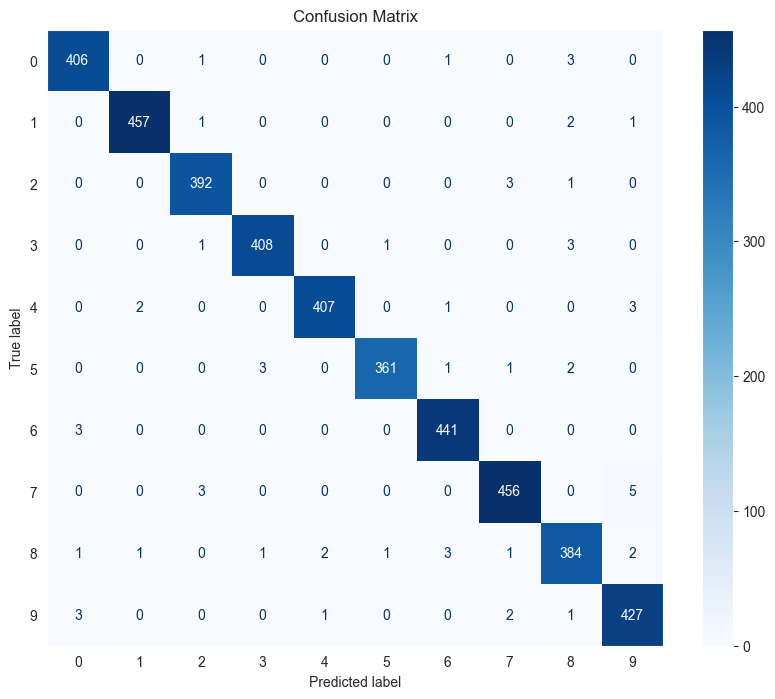

Experiment with kernel [(3, 1), (1, 3)] and optimizer: Adam 
Epoch [1/10]
  Train -> Loss: 1.8012 | Accuracy: 0.6354 | Precision: 0.6387 | Recall: 0.6305 | F1: 0.6263
  Valid -> Loss: 0.9198 | Accuracy: 0.7912 | Precision: 0.8106 | Recall: 0.7855 | F1: 0.7857
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 1.1871 | Accuracy: 0.7505 | Precision: 0.7573 | Recall: 0.7465 | F1: 0.7454
  Valid -> Loss: 0.5762 | Accuracy: 0.8555 | Precision: 0.8661 | Recall: 0.8515 | F1: 0.8522
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.9452 | Accuracy: 0.8075 | Precision: 0.8248 | Recall: 0.8042 | F1: 0.8065
  Valid -> Loss: 0.4422 | Accuracy: 0.8812 | Precision: 0.8956 | Recall: 0.8782 | F1: 0.8797
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.8016 | 

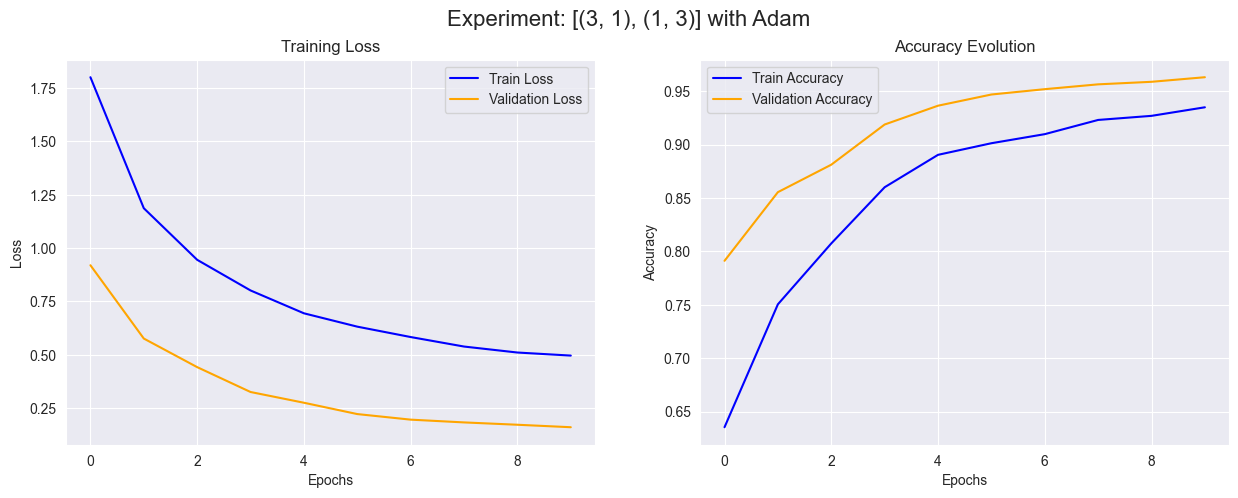

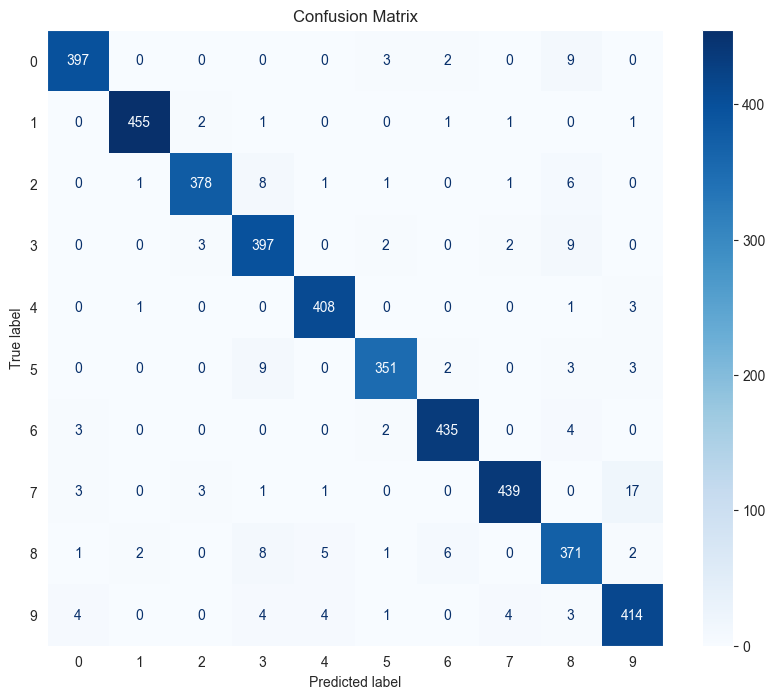

In [25]:
for kernel in configs:
    run_experiment(kernel, "Adam", 10, train_loader_aug, val_loader, augmentation=True)

In [26]:
pd.DataFrame(results_summary).sort_values("Final Validation F1-Score", ascending=False)

,Model,Kernels,Optimizer,Augmentation,Final Validation Accuracy,Final Validation Precision,Final Validation Recall,Final Validation F1-Score,Epochs
8,CNN-Base,"[(7, 7), (5, 5)]",RMSProp,False,0.987381,0.987426,0.987247,0.987321,10
25,CNN-Base,"[(7, 7), (5, 5)]",Adam,True,0.985476,0.985496,0.985297,0.985386,10
0,CNN-Base,"[(5, 5), (3, 3)]",Adam,False,0.985000,0.984957,0.984951,0.984919,10
1,CNN-Base,"[(3, 3), (3, 3)]",Adam,False,0.984762,0.984778,0.984621,0.984676,10
6,CNN-Base,"[(3, 3), (3, 3)]",RMSProp,False,0.984762,0.984496,0.984663,0.984541,10
3,CNN-Base,"[(7, 7), (5, 5)]",Adam,False,0.983333,0.983294,0.982968,0.983077,10
21,CNN-Base,"[(5, 5), (3, 3)]",Adam,True,0.983095,0.983107,0.982838,0.982950,10
23,CNN-Base,"[(3, 3), (3, 3)]",Adam,True,0.982619,0.982629,0.982423,0.982505,10
18,Le-Net5,"[(5,5), (5,5)]",Adam,False,0.982143,0.982042,0.981961,0.981957,10
22,CNN-Base,"[(5, 5), (3, 3)]",Adam,True,0.981905,0.981930,0.981645,0.981751,10


In [15]:
def visualize_all_convolutional_layers(model, loader, model_name="Model"):
    model.eval()
    images, _ = next(iter(loader))
    x = images[0].unsqueeze(0)
    
    activations = {}

    def get_activation(name):
        def hook(model, input, output):
            activations[name] = output.detach()
        return hook

    for name, layer in model.named_modules():
        if isinstance(layer, nn.Conv2d):
            layer.register_forward_hook(get_activation(name))

    with torch.no_grad():
        model(x)

    for layer_name, feature_maps in activations.items():
        num_filters = feature_maps.size(1)
        
        cols = 8
        rows = (num_filters + cols - 1) // cols
        
        fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2))
        fig.suptitle(f"{model_name} | Layer: {layer_name} | Filters: {num_filters}", fontsize=16)
        
        for i in range(rows * cols):
            ax = axes[i // cols, i % cols] if rows > 1 else axes[i]
            if i < num_filters:
                ax.imshow(feature_maps[0, i].numpy(), cmap='viridis')
            ax.axis('off')
            
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()



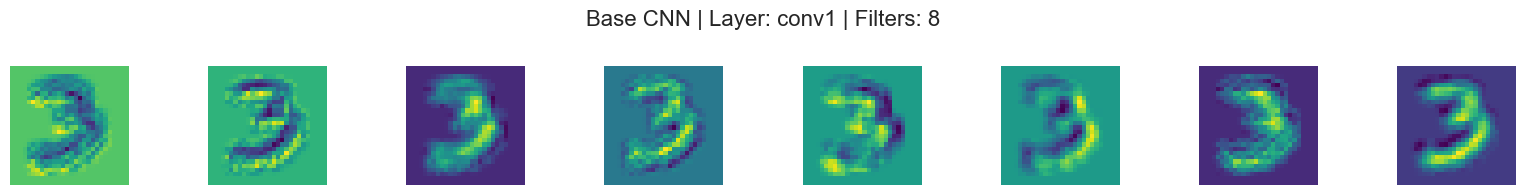

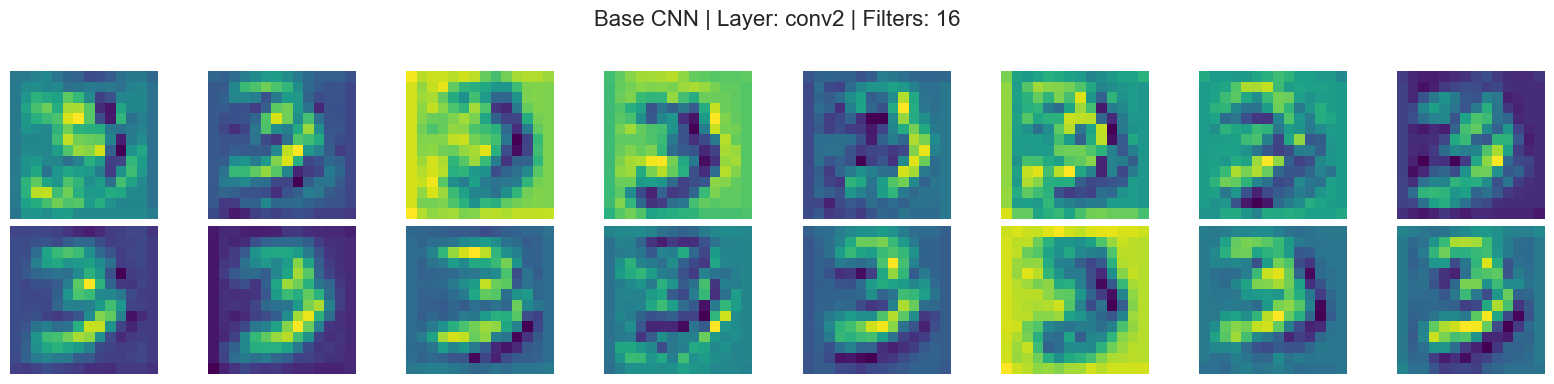

In [16]:
visualize_all_convolutional_layers(ConvolutionalNeuralNetwork([(5,5), (3,3)]), val_loader, "Base CNN")

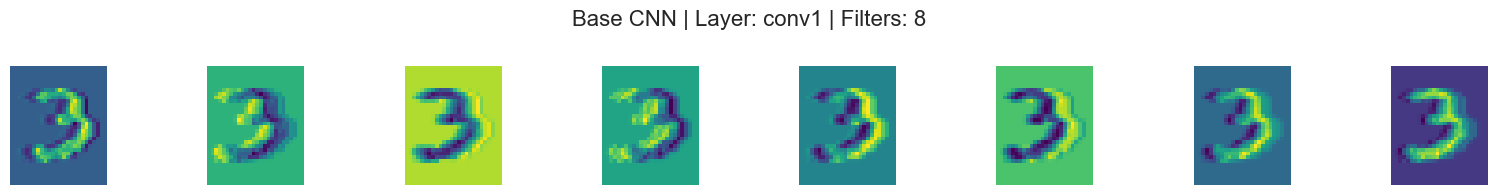

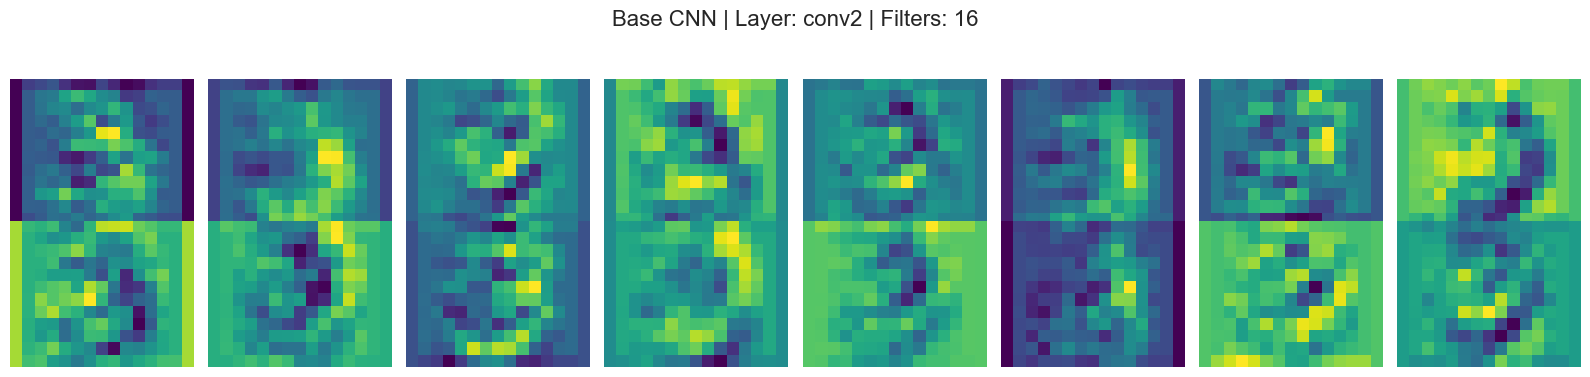

In [17]:
visualize_all_convolutional_layers(ConvolutionalNeuralNetwork([(1,7), (7,1)]), val_loader, "Base CNN")

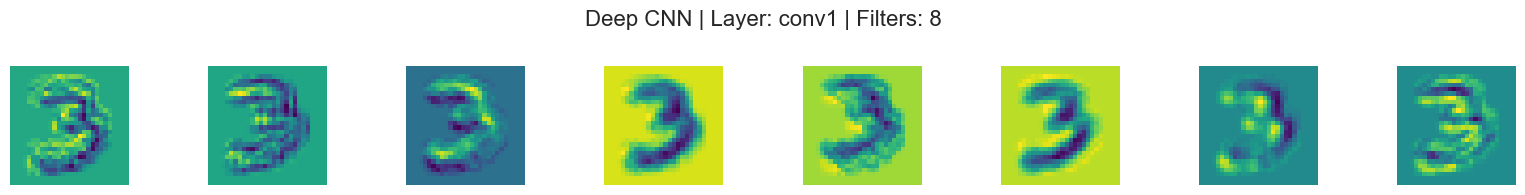

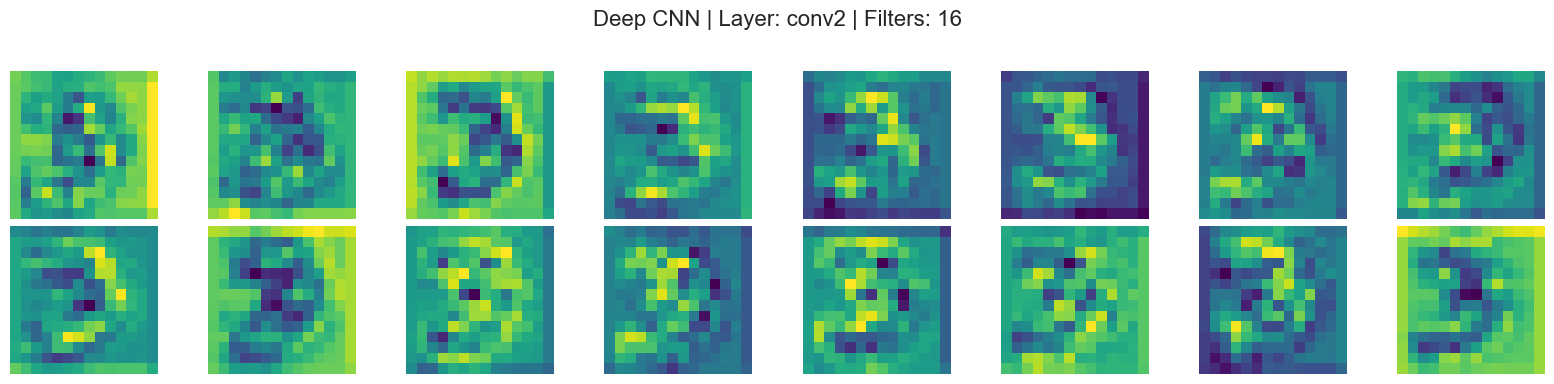

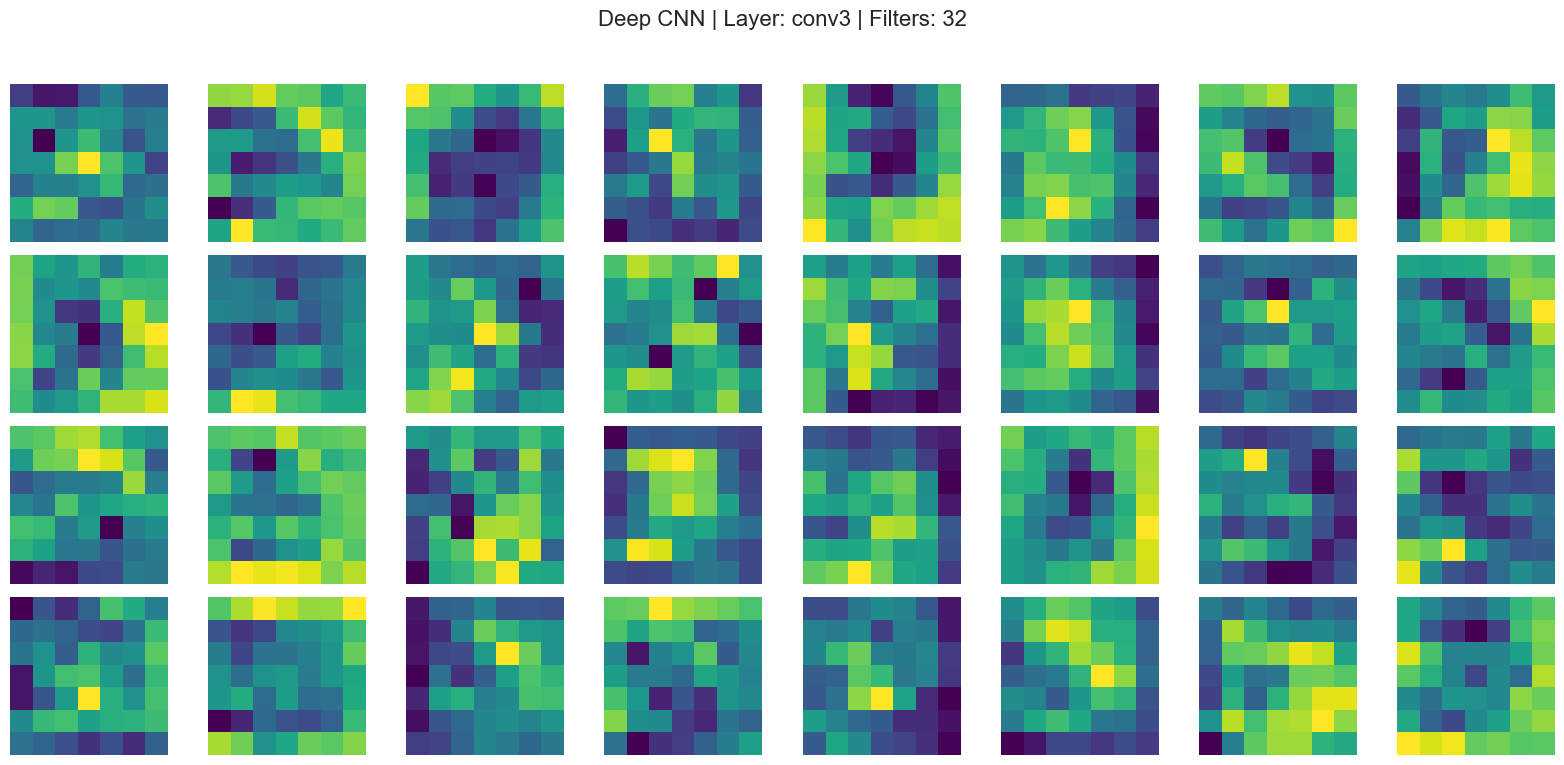

In [18]:
visualize_all_convolutional_layers(DeepConvolutionalNeuralNetwork([(5,5), (3,3), (3,3)]), val_loader, "Deep CNN")

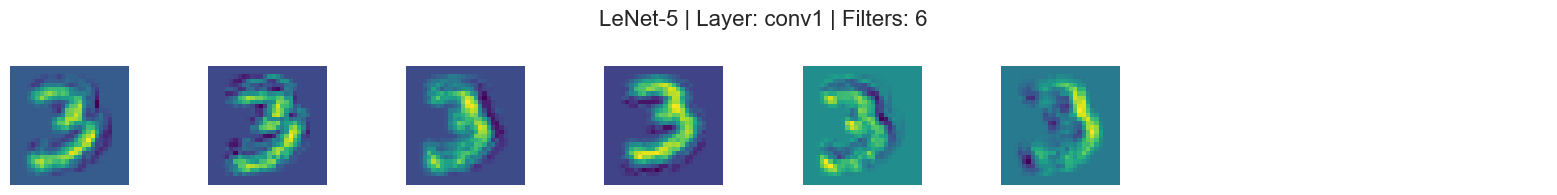

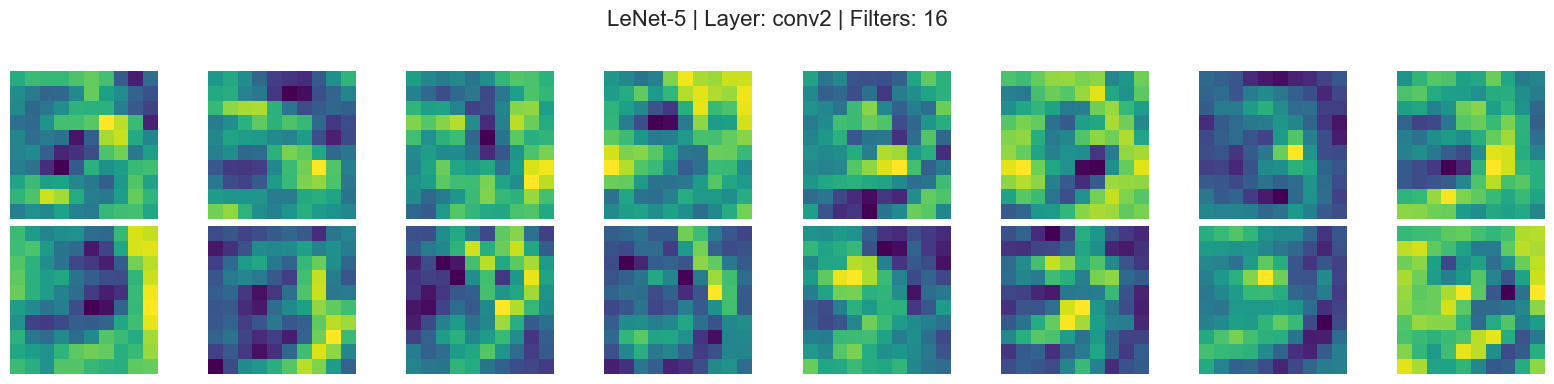

In [19]:
visualize_all_convolutional_layers(LeNet5(), val_loader, "LeNet-5")

In [63]:
model_base = ConvolutionalNeuralNetwork([(5,5), (3,3)])
model_deep = DeepConvolutionalNeuralNetwork([(5,5), (3,3), (3,3)])
model_lenet = LeNet5()

opt_base = optim.Adam(model_base.parameters(), lr=0.001)
opt_deep = optim.Adam(model_deep.parameters(), lr=0.001)
opt_lenet = optim.Adam(model_lenet.parameters(), lr=0.001)

print("Training Base CNN...")
perform_learning(model_base, 10, opt_base, train_loader_plain, val_loader)

print("\nTraining Deep CNN...")
perform_learning(model_deep, 10, opt_deep, train_loader_plain, val_loader)

print("\nTraining LeNet-5...")
perform_learning(model_lenet, 10, opt_lenet, train_loader_plain, val_loader)

trained_models = [model_base, model_deep, model_lenet]

Training Base CNN...
Epoch [1/10]
  Train -> Loss: 0.8385 | Accuracy: 0.9239 | Precision: 0.9246 | Recall: 0.9232 | F1: 0.9233
  Valid -> Loss: 0.2484 | Accuracy: 0.9343 | Precision: 0.9351 | Recall: 0.9334 | F1: 0.9337
----------------------------------------------------------------------------------------------------
Epoch [2/10]
  Train -> Loss: 0.2891 | Accuracy: 0.9620 | Precision: 0.9619 | Recall: 0.9617 | F1: 0.9617
  Valid -> Loss: 0.1371 | Accuracy: 0.9621 | Precision: 0.9617 | Recall: 0.9619 | F1: 0.9617
----------------------------------------------------------------------------------------------------
Epoch [3/10]
  Train -> Loss: 0.1928 | Accuracy: 0.9725 | Precision: 0.9724 | Recall: 0.9723 | F1: 0.9723
  Valid -> Loss: 0.0989 | Accuracy: 0.9717 | Precision: 0.9717 | Recall: 0.9713 | F1: 0.9714
----------------------------------------------------------------------------------------------------
Epoch [4/10]
  Train -> Loss: 0.1541 | Accuracy: 0.9783 | Precision: 0.9783 | R

In [27]:
def evaluate_ensemble(models, loader):
    for model in models:
        model.eval()
    
    all_predictions, all_labels = [], []
    
    with torch.no_grad():
        for images, labels in loader:
            ensemble_probs = []
            for model in models:
                probs = torch.softmax(model(images), dim=1)
                ensemble_probs.append(probs)
            
            avg_probs = torch.mean(torch.stack(ensemble_probs), dim=0)
            _, prediction = torch.max(avg_probs, 1)
            
            all_predictions.extend(prediction.numpy())
            all_labels.extend(labels.numpy())
            
    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(all_labels, all_predictions, average='macro')
    recall = recall_score(all_labels, all_predictions, average='macro')
    f1 = f1_score(all_labels, all_predictions, average='macro')
    
    return accuracy, precision, recall, f1, all_predictions, all_labels

In [66]:
ens_accuracy, ens_precision, ens_recall, ens_f1, ens_preds, ens_labels = evaluate_ensemble(trained_models, val_loader)

results_summary.append({
    "Model": "Ensemble (Base+Deep+LeNet)",
    "Kernels": "Mixed",
    "Optimizer": "Adam", 
    "Augmentation": "False",
    "Final Validation Accuracy": ens_accuracy,
    "Final Validation Precision": ens_precision,
    "Final Validation Recall": ens_recall,
    "Final Validation F1-Score": ens_f1,
    "Epochs": 10
})

df_results = pd.DataFrame(results_summary).sort_values("Final Validation F1-Score", ascending=False)

                         Model           Kernels Optimizer Augmentation  \
27  Ensemble (Base+Deep+LeNet)             Mixed      Adam        False   
8                     CNN-Base  [(7, 7), (5, 5)]   RMSProp        False   
25                    CNN-Base  [(7, 7), (5, 5)]      Adam         True   
0                     CNN-Base  [(5, 5), (3, 3)]      Adam        False   
1                     CNN-Base  [(3, 3), (3, 3)]      Adam        False   

    Final Validation Accuracy  Final Validation Precision  \
27                   0.988333                    0.988347   
8                    0.987381                    0.987426   
25                   0.985476                    0.985496   
0                    0.985000                    0.984957   
1                    0.984762                    0.984778   

    Final Validation Recall  Final Validation F1-Score  Epochs  
27                 0.988326                   0.988331       5  
8                  0.987247                   0.9873

In [67]:
df_results

,Model,Kernels,Optimizer,Augmentation,Final Validation Accuracy,Final Validation Precision,Final Validation Recall,Final Validation F1-Score,Epochs
27,Ensemble (Base+Deep+LeNet),Mixed,Adam,False,0.988333,0.988347,0.988326,0.988331,5
8,CNN-Base,"[(7, 7), (5, 5)]",RMSProp,False,0.987381,0.987426,0.987247,0.987321,10
25,CNN-Base,"[(7, 7), (5, 5)]",Adam,True,0.985476,0.985496,0.985297,0.985386,10
0,CNN-Base,"[(5, 5), (3, 3)]",Adam,False,0.985000,0.984957,0.984951,0.984919,10
1,CNN-Base,"[(3, 3), (3, 3)]",Adam,False,0.984762,0.984778,0.984621,0.984676,10
6,CNN-Base,"[(3, 3), (3, 3)]",RMSProp,False,0.984762,0.984496,0.984663,0.984541,10
3,CNN-Base,"[(7, 7), (5, 5)]",Adam,False,0.983333,0.983294,0.982968,0.983077,10
21,CNN-Base,"[(5, 5), (3, 3)]",Adam,True,0.983095,0.983107,0.982838,0.982950,10
23,CNN-Base,"[(3, 3), (3, 3)]",Adam,True,0.982619,0.982629,0.982423,0.982505,10
18,Le-Net5,"[(5,5), (5,5)]",Adam,False,0.982143,0.982042,0.981961,0.981957,10


In [25]:
model_one = ConvolutionalNeuralNetwork([(7,7), (5,5)])
model_two = ConvolutionalNeuralNetwork([(7,7), (5,5)])
model_three = ConvolutionalNeuralNetwork([(5,5), (3,3)])

opt_one = optim.RMSprop(model_one.parameters(), lr=0.001)
opt_two = optim.Adam(model_two.parameters(), lr=0.001)
opt_three = optim.Adam(model_three.parameters(), lr=0.001)

print("Training Model One...")
history_one = perform_learning(model_one, 20, opt_one, train_loader_plain, val_loader)

print("\nTraining Model Two...")
history_two = perform_learning(model_two, 20, opt_two, train_loader_plain, val_loader)

print("\nTraining Model Three   ...")
history_three = perform_learning(model_three, 20, opt_three, train_loader_plain, val_loader)

trained_models = [model_one, model_two, model_three]

Training Model One...
Epoch [1/20]
  Train -> Loss: 0.4159 | Accuracy: 0.9563 | Precision: 0.9576 | Recall: 0.9566 | F1: 0.9563
  Valid -> Loss: 0.1501 | Accuracy: 0.9540 | Precision: 0.9552 | Recall: 0.9543 | F1: 0.9538
----------------------------------------------------------------------------------------------------
Epoch [2/20]
  Train -> Loss: 0.1651 | Accuracy: 0.9723 | Precision: 0.9724 | Recall: 0.9724 | F1: 0.9723
  Valid -> Loss: 0.0886 | Accuracy: 0.9710 | Precision: 0.9710 | Recall: 0.9707 | F1: 0.9707
----------------------------------------------------------------------------------------------------
Epoch [3/20]
  Train -> Loss: 0.1285 | Accuracy: 0.9807 | Precision: 0.9807 | Recall: 0.9808 | F1: 0.9807
  Valid -> Loss: 0.0681 | Accuracy: 0.9805 | Precision: 0.9803 | Recall: 0.9804 | F1: 0.9803
----------------------------------------------------------------------------------------------------
Epoch [4/20]
  Train -> Loss: 0.1119 | Accuracy: 0.9831 | Precision: 0.9832 | 

In [28]:
ens_accuracy_new, ens_precision_new, ens_recall_new, ens_f1_new, ens_preds_new, ens_labels_new = evaluate_ensemble(trained_models, val_loader)


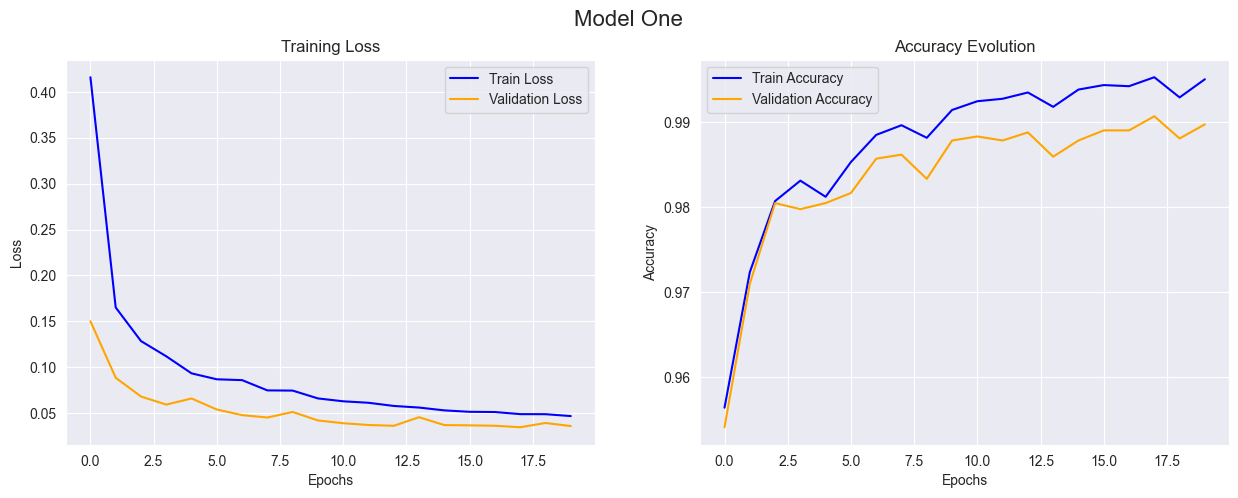

In [39]:
plot_history(history_one, "Model One")

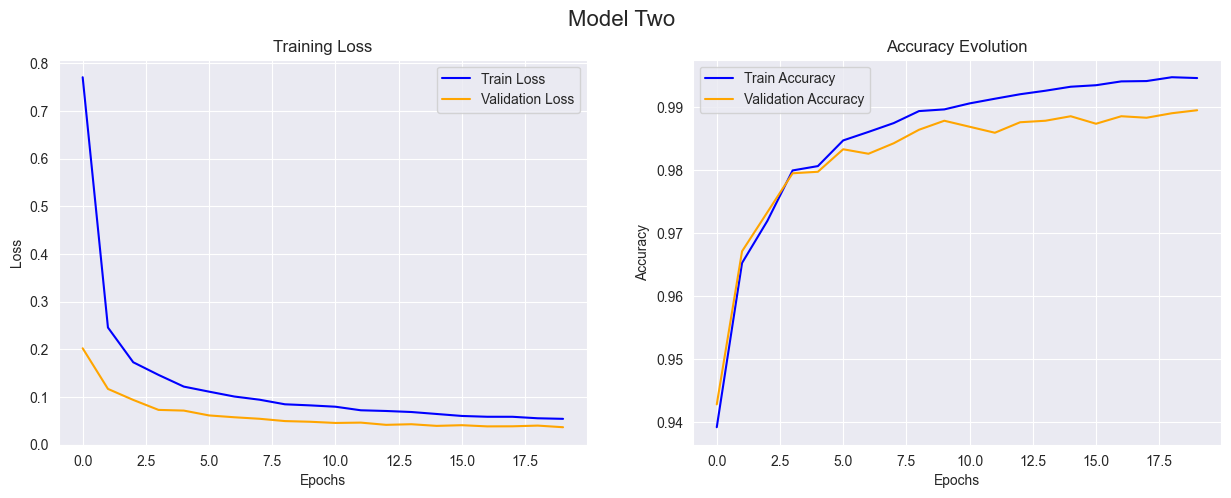

In [41]:
plot_history(history_two, "Model Two")

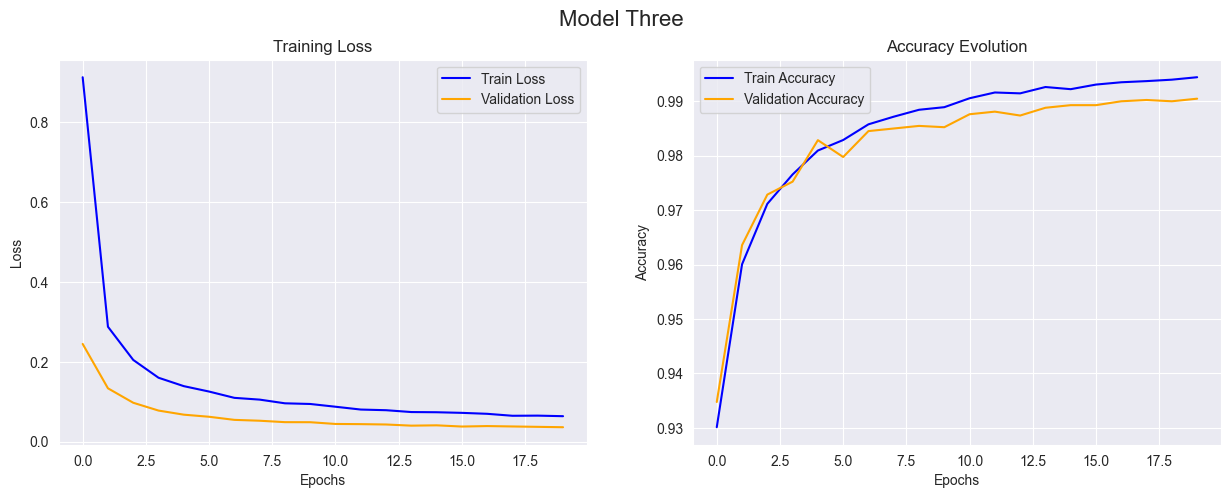

In [42]:
plot_history(history_three, "Model Three")

In [32]:
print(f"Accuracy: {ens_accuracy_new}")
print(f"Precision: {ens_accuracy_new}")
print(f"Recall: {ens_recall_new}")
print(f"F1-Score: {ens_f1_new}")

Accuracy: 0.9911904761904762
Precision: 0.9911904761904762
Recall: 0.9912537464879095
F1-Score: 0.9911790529668432


In [36]:
test_raw = pd.read_csv("test.csv")
test_dataset = DigitDataset(test_raw, is_test=True, transform=None)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [34]:
def generate_kaggle_submission(models, loader, file_name="submission.csv"):
    for model in models:
        model.eval()
    
    final_predictions = []
    
    with torch.no_grad():
        for images in loader:
            ensemble_probs = []
            for model in models:
                probs = torch.softmax(model(images), dim=1)
                ensemble_probs.append(probs)
            
            avg_probs = torch.mean(torch.stack(ensemble_probs), dim=0)
            
            _, preds = torch.max(avg_probs, 1)
            final_predictions.extend(preds.numpy())
            
    submission = pd.DataFrame({
        "ImageId": np.arange(1, len(final_predictions) + 1),
        "Label": final_predictions
    })
    
    submission.to_csv(file_name, index=False)
    print(f"File '{file_name}' saved successfully!")
    return submission


In [37]:
kaggle_sub = generate_kaggle_submission(trained_models, test_loader, file_name="kaggle_submission.csv")

File 'kaggle_submission.csv' saved successfully!
